## Настройка среды

In [1]:
import math
import re
import sys
from collections import Counter, defaultdict
from contextlib import contextmanager
from functools import lru_cache, partial
from hashlib import sha256
from html import unescape
from pathlib import Path
from time import perf_counter
from unicodedata import normalize

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import pycld2 as cld2
import regex
import spacy
from ftfy import fix_encoding
from nltk.corpus import stopwords, wordnet
from nltk.lm import KneserNeyInterpolated, NgramCounter, Vocabulary
from nltk.lm import smoothing as lm_smoothing
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import regexp_tokenize
from sklearn.model_selection import train_test_split
from spacy.tokens import Doc


> ‼️Раскомментируйте при первом запуске.

In [2]:
# ! mkdir -p ../data/raw
# ! curl -L -o ../data/raw/myanimelist-comment-dataset-v2.zip \
#     https://www.kaggle.com/api/v1/datasets/download/natlee/myanimelist-comment-dataset-v2
# ! unzip -d ../data/raw -o ../data/raw/myanimelist-comment-dataset-v2.zip

In [3]:
RANDOM_STATE = 13112026

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = PROJECT_ROOT / 'data' / 'raw'

In [4]:
# Ресурсы храним в виртуальном окружении проекта, доступном ядру ноутбука.
for resource in ('stopwords', 'wordnet', 'averaged_perceptron_tagger_eng', 'universal_tagset'):
    nltk.download(resource, download_dir=str(PROJECT_ROOT / '.venv' / 'nltk_data'))


[nltk_data] Downloading package stopwords to /home/lighter_01/projects
[nltk_data]     /itmo/NLP/nlp_labs/.venv/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/lighter_01/projects/i
[nltk_data]     tmo/NLP/nlp_labs/.venv/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to /hom
[nltk_data]     e/lighter_01/projects/itmo/NLP/nlp_labs/.venv/nltk_dat
[nltk_data]     a...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package universal_tagset to /home/lighter_01/p
[nltk_data]     rojects/itmo/NLP/nlp_labs/.venv/nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


---

## Загрузка и первичная очистка

In [5]:
df_reviews = pd.read_csv(DATASET_PATH / 'reviews.csv', header=0)
df_al = pd.read_csv(DATASET_PATH / 'anime_list.csv', header=0)

In [6]:
df_reviews.head(3)

,id,workId,url,workName,postTime,episodesSeen,overallRating,author,reviewId,review,recommendationStatus,nice,loveIt,funny,confusing,informative,wellWritten,creative
0,155870,196,https://myanimelist.net/anime/196/Onegai%E2%98...,Onegai%E2%98%86Twins,"Apr 1, 2008",NaN,7,CapitalJ,3533,The plot is pretty interesting at first but I ...,Recommended,6,0,0,0,0,0,0
1,245390,934,https://myanimelist.net/anime/934/Higurashi_no...,Higurashi_no_Naku_Koro_ni,"Apr 1, 2008",NaN,10,merQree,3538,I haven't watched many anime's yet but so far ...,Recommended,9,0,0,0,0,0,0
2,269080,3229,https://myanimelist.net/anime/3229/Kimi_ga_Aru...,Kimi_ga_Aruji_de_Shitsuji_ga_Ore_de,"Apr 1, 2008",NaN,8,Master10K,3525,"They Are My Noble Masters is a Harem, Ecchi, R...",Recommended,65,0,0,0,0,0,0


In [7]:
df_al.head(3)

,id,workId,url,jpName,engName,synonymsName,workType,episodes,status,aired,...,source,duration,rating,score,allRank,popularityRank,members,favorites,scoredByUser,lastUpdate
0,1,47917,https://myanimelist.net/anime/47917/Bocchi_the...,ぼっち・ざ・ろっく！,Bocchi the Rock!,NaN,TV,12,Finished Airing,"Oct 9, 2022 to Dec 25, 2022",...,4-koma manga,23 min. per ep.,PG-13 - Teens 13 or older,8.86,#27,#509,"415,475","20,435",241578.0,2023-06-02 00:11:01
1,2,19,https://myanimelist.net/anime/19/Monster,モンスター,Monster,NaN,TV,74,Finished Airing,"Apr 7, 2004 to Sep 28, 2005",...,Manga,24 min. per ep.,R+ - Mild Nudity,8.87,#26,#142,"1,006,450","46,856",365316.0,2023-06-02 00:11:10
2,3,35247,https://myanimelist.net/anime/35247/Owarimonog...,終物語,Owarimonogatari Second Season,End Story 2nd Season,TV,7,Finished Airing,"Aug 12, 2017 to Aug 13, 2017",...,Light novel,22 min. per ep.,R - 17+ (violence & profanity),8.88,#25,#567,"379,309","8,444",182679.0,2023-06-02 00:11:19


In [8]:
df = pd.merge(df_reviews, df_al, on='workId', how='left', validate='many_to_one')

In [9]:
del df_reviews, df_al

In [10]:
df.head(3)

,id_x,workId,url_x,workName,postTime,episodesSeen,overallRating,author,reviewId,review,...,source,duration,rating,score,allRank,popularityRank,members,favorites,scoredByUser,lastUpdate
0,155870,196,https://myanimelist.net/anime/196/Onegai%E2%98...,Onegai%E2%98%86Twins,"Apr 1, 2008",NaN,7,CapitalJ,3533,The plot is pretty interesting at first but I ...,...,Original,25 min. per ep.,PG-13 - Teens 13 or older,6.82,#4750,#2105,"87,596",187,49084.0,2023-06-02 03:59:44
1,245390,934,https://myanimelist.net/anime/934/Higurashi_no...,Higurashi_no_Naku_Koro_ni,"Apr 1, 2008",NaN,10,merQree,3538,I haven't watched many anime's yet but so far ...,...,Visual novel,24 min. per ep.,R - 17+ (violence & profanity),7.89,#746,#223,"778,866","20,723",382783.0,2023-06-02 00:47:41
2,269080,3229,https://myanimelist.net/anime/3229/Kimi_ga_Aru...,Kimi_ga_Aruji_de_Shitsuji_ga_Ore_de,"Apr 1, 2008",NaN,8,Master10K,3525,"They Are My Noble Masters is a Harem, Ecchi, R...",...,Visual novel,25 min. per ep.,R+ - Mild Nudity,7.11,#3492,#1743,"115,853",227,53119.0,2023-06-02 03:00:04


In [11]:
df.columns

Index(['id_x', 'workId', 'url_x', 'workName', 'postTime', 'episodesSeen',
       'overallRating', 'author', 'reviewId', 'review', 'recommendationStatus',
       'nice', 'loveIt', 'funny', 'confusing', 'informative', 'wellWritten',
       'creative', 'id_y', 'url_y', 'jpName', 'engName', 'synonymsName',
       'workType', 'episodes', 'status', 'aired', 'premiered', 'producer',
       'broadcast', 'licensors', 'studios', 'genres', 'themes', 'demographic',
       'source', 'duration', 'rating', 'score', 'allRank', 'popularityRank',
       'members', 'favorites', 'scoredByUser', 'lastUpdate'],
      dtype='str')

In [12]:
drop_cols = [
    'id_x', 'workId', 'url_x', 'postTime', 'episodesSeen',
    'author', 'reviewId', 'nice', 'loveIt', 'funny',
    'confusing', 'informative', 'wellWritten', 'creative', 'id_y', 'url_y', 
    'jpName', 'workType', 'episodes', 'status', 'aired', 'premiered', 'producer',
    'broadcast', 'licensors', 'studios', 'genres', 'themes', 'demographic',
    'source', 'duration', 'rating', 'score', 'allRank', 'popularityRank',
    'members', 'favorites', 'scoredByUser', 'lastUpdate'
]

df = df.drop(columns=drop_cols)
df.head(3)

,workName,overallRating,review,recommendationStatus,engName,synonymsName
0,Onegai%E2%98%86Twins,7,The plot is pretty interesting at first but I ...,Recommended,Please Twins!,Onegai☆Twins
1,Higurashi_no_Naku_Koro_ni,10,I haven't watched many anime's yet but so far ...,Recommended,Higurashi: When They Cry,"When the Cicadas Cry, The Moment the Cicadas Cry"
2,Kimi_ga_Aruji_de_Shitsuji_ga_Ore_de,8,"They Are My Noble Masters is a Harem, Ecchi, R...",Recommended,They Are My Noble Masters,Kimiaru


In [13]:
df.shape

(224641, 6)

In [14]:
df.isna().sum()

workName                    0
overallRating               0
review                      0
recommendationStatus    71938
engName                 21358
synonymsName            77494
dtype: int64

**Подготовка двух потенциальных таргетов датасета**

В исходной колонке `recommendationStatus` встречаются только `Recommended` и пропуски. Поэтому бинарный признак определяем как наличие этой отметки: `True` — есть `Recommended`, `False` — отметка отсутствует. По самому CSV нельзя установить, означает ли каждый пропуск именно отрицательную рекомендацию; это ограничение интерпретации целевого признака.

`overallRating` оставляем запасным таргетом. Фильтр ниже исключает одну запись с нулевой оценкой, чтобы в этой колонке оставались только оценки от 1 до 10. Для текущего бинарного таргета этот фильтр сам по себе не обязателен.

In [15]:
df['overallRating'].value_counts()

overallRating
10    42936
9     39669
8     39433
7     32296
6     22002
5     15394
4     11203
3     10268
2      5804
1      5635
0         1
Name: count, dtype: int64

In [16]:
# df = df[df['overallRating'] != 0]
df = df.query('overallRating != 0')
np.sort(df['overallRating'].unique())

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [17]:
df['recommendationStatus'].value_counts(dropna=False)

recommendationStatus
Recommended    152703
NaN             71937
Name: count, dtype: int64

In [18]:
df['recommendationStatus'] = df['recommendationStatus'].notna()
df['recommendationStatus'].value_counts()

recommendationStatus
True     152703
False     71937
Name: count, dtype: int64

**Повторяющиеся тексты**

До разделения выборки исключаем все строки, текст `review` которых повторяется (`keep=False`). Это предотвращает попадание одинакового текста в Train и Test. У семи групп повторов бинарные метки расходятся, поэтому удаляем все копии, не выбирая произвольно одну из меток. Проверка проводится по точному совпадению исходных текстов; похожие, но не идентичные отзывы здесь не объединяем.

In [19]:
duplicate_reviews_mask = df['review'].duplicated(keep=False)
print(f'Number of rows with duplicate reviews: {duplicate_reviews_mask.sum()}')

df = df[~duplicate_reviews_mask].copy()
df.shape

Number of rows with duplicate reviews: 464


(224176, 6)

**Языковая подготовка и технические дубликаты**

С помощью CLD2 (`pycld2`) выделяем английские части смешанных отзывов. Документ исключаем, если английский текст не обнаружен. В преимущественно английском отзыве удаляем неанглийские участки длиной не менее 80 букв: короткие имена и заимствования сохраняем. На коротких фрагментах определение языка может быть неточным.

После языкового отбора исключаем все копии технически одинаковых отзывов (`keep=False`). Для сравнения учитываем HTML-сущности, служебную вставку, пробелы, регистр и варианты кавычек. Оба этапа выполняются до разбиения, чтобы одинаковые тексты не попадали одновременно в Train и Test.


In [20]:
# Управляющие символы для замены во временном входе CLD2; табуляцию, LF и CR оставляем.
language_control_pattern = re.compile(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]')

#============================================================

# Служебные заголовки известных языковых версий смешанного отзыва.
language_heading_pattern = re.compile(
    r'^[ \t=*_—-]*(?:en\s+espa[ñn]ol|part\s*[12]\s*[:.-]?\s*(?:english|bahasa\s+indonesia))[ \t:.*_=—-]*\r?$',
    re.MULTILINE | re.IGNORECASE
)


def keep_english_parts(s, min_foreign_letters=80):
    """
    Выделяет английский текст по CLD2; исключаемый документ обозначает None.

    В преимущественно английском отзыве короткие неанглийские фрагменты сохраняются.
    """
    # Готовим временную копию для детектора: один управляющий символ заменяем одним пробелом.
    # Позиции символов остаются теми же, хотя число байтов UTF-8 может измениться.
    language_view = language_control_pattern.sub(' ', s)
    # Получаем общую оценку языка и фрагменты с байтовыми смещениями.
    _, _, details, spans = cld2.detect(language_view, isPlainText=True, bestEffort=True, returnVectors=True)
    encoded_text = language_view.encode('utf-8')
    primary_language = details[0][1]
    has_english = False
    remove_spans = []
    
    # Ищем английские части и собираем диапазоны, подлежащие удалению.
    for start, length, _, language_code in spans:
        fragment = encoded_text[start:start + length].decode('utf-8')
        if language_code == 'en' and any(char.isalpha() for char in fragment):
            has_english = True
        # un означает неопределённый язык: такие участки сохраняем.
        elif language_code not in {'en', 'un'}:
            # Порог считаем по буквам всех алфавитов, распознаваемым str.isalpha().
            letters = sum(char.isalpha() for char in fragment)
            # При основном en действует порог 80; при другом основном языке — любой размер.
            if primary_language != 'en' or letters >= min_foreign_letters:
                # CLD2 возвращает байтовые смещения; переводим их в позиции символов.
                char_start = len(encoded_text[:start].decode('utf-8'))
                char_end = char_start + len(fragment)
                remove_spans.append((char_start, char_end))
    
    # Исключаем документ, если нет английского фрагмента и общая оценка языка тоже не en.
    if not has_english and primary_language != 'en':
        return None
    # Если удалять нечего, возвращаем исходную строку без изменений.
    if not remove_spans:
        return s
    
    # При выделении английской версии убираем её служебные языковые заголовки.
    # Заголовок может пересекать границу двух сегментов CLD2.
    remove_spans.extend(match.span() for match in language_heading_pattern.finditer(s))
    # Объединяем пересекающиеся диапазоны, чтобы не вырезать один участок дважды.
    merged_spans = []
    for start, end in sorted(remove_spans):
        if merged_spans and start <= merged_spans[-1][1]:
            merged_spans[-1] = (merged_spans[-1][0], max(end, merged_spans[-1][1]))
        else:
            merged_spans.append((start, end))
    
    # Собираем сохранённые части исходной строки; их границы заданы в символах.
    parts = []
    cursor = 0
    for start, end in merged_spans:
        parts.append(s[cursor:start])
        cursor = end
    parts.append(s[cursor:])
    # Разделяем части абзацами, чтобы слова по сторонам удалённого блока не склеились.
    result = '\n\n'.join(part for part in parts if part.strip())
    # Удаляем остатки заголовков и проверяем, что в результате сохранились буквы.
    result = language_heading_pattern.sub('', result).strip()
    return result if any(char.isalpha() for char in result) else None

In [21]:
english_reviews = df['review'].map(keep_english_parts)
english_reviews_mask = english_reviews.notna()
num_language_removed = (~english_reviews_mask).sum()
num_language_trimmed = (english_reviews_mask & english_reviews.ne(df['review'])).sum()
print(f'Reviews without detected English text removed: {num_language_removed}')
print(f'Mixed-language reviews with English parts retained: {num_language_trimmed}')

df = df[english_reviews_mask].copy()
df['review'] = english_reviews.loc[df.index]
df.shape

Reviews without detected English text removed: 349
Mixed-language reviews with English parts retained: 1909


(223827, 6)

In [22]:
# Служебная вставка сайта: многоточие с переносами строк и большими отступами.
review_ui_pattern = re.compile(r'\n[ \t]{5,}\.\.\.[ \t]*\r?\n[ \t]{5,}')
# Все пробельные последовательности приводим к одному пробелу при сравнении.
comparison_spaces_pattern = re.compile(r'\s+')

#============================================================

# Подготовка ключа сравнения; эти функции не переписывают колонку review.
def comparison_view(s):
    """Возвращает представление текста без выбранных различий в оформлении."""
    # Убираем служебную вставку, затем декодируем HTML-сущности одним проходом.
    s = unescape(review_ui_pattern.sub(' ', s))
    # Унифицируем правый типографский апостроф и двойные кавычки.
    s = s.replace('’', "'").replace('“', '"').replace('”', '"')
    # Схлопываем пробелы и переносы, убираем отступы по краям, объединяем регистр.
    return comparison_spaces_pattern.sub(' ', s).strip().casefold()


def review_format_key(s):
    """Вычисляет SHA-256 от UTF-8-представления строки сравнения."""
    return sha256(comparison_view(s).encode('utf-8')).hexdigest()

In [23]:
review_format_keys = df['review'].map(review_format_key)
duplicate_format_mask = review_format_keys.duplicated(keep=False)
print(f'Additional rows with technically duplicate reviews removed: {duplicate_format_mask.sum()}')

df = df[~duplicate_format_mask].copy()
df.shape

Additional rows with technically duplicate reviews removed: 106


(223721, 6)

---

---

## 1.

Загрузите ваш индивидуальный датасет. Выделите целевую текстовую колонку. Разделите выборку на обучающую (Train) и тестовую (Test) в соотношении 80/20 с применением стратификации по целевому классу.

In [24]:
df_train, df_test = train_test_split(df, test_size=0.2, stratify=df['recommendationStatus'], random_state=RANDOM_STATE)
df_train.shape, df_test.shape

((178976, 6), (44745, 6))

In [25]:
pd.DataFrame({
    'All': df['recommendationStatus'].value_counts(normalize=True),
    'Train': df_train['recommendationStatus'].value_counts(normalize=True),
    'Test': df_test['recommendationStatus'].value_counts(normalize=True)
})

,All,Train,Test
recommendationStatus,,,
True,0.679342,0.679342,0.679338
False,0.320658,0.320658,0.320662


---

## 2.

> Исследуйте структуру данных строго на обучающей выборке: подсчитайте общее количество документов, среднюю длину текстов в словах и символах. Постройте графики распределения длин текстов и частоты топ-30 стоп-слов.

Статистики считаем по `df_train['review']` до очистки из задания 4.

Словом считаем последовательность букв или цифр с возможными комбинируемыми знаками и внутренним апострофом. Слова с отдельным акцентом сохраняются целиком, `don't` считается одним словом. Подчёркивания, пунктуация и эмодзи `❤️` не учитываются; дефис и десятичная точка разделяют токены. Длина в символах — `len(s)`, включая пробелы и переносы строк.

Для топ-30 используем английский список стоп-слов NLTK; при подсчёте приводим слова к нижнему регистру и единому апострофу. Гистограммы охватывают весь диапазон длин: вертикальная шкала логарифмическая, пунктиром отмечено среднее.


**Вариант 1: токенизация через NLTK.**


In [26]:
def investigate_df(df, text_col: str = 'review'):
    docs: pd.Series = df[text_col]
    word_pattern = (r"[\p{L}\p{N}][\p{L}\p{M}\p{N}]*"
                    r"(?:['’][\p{L}\p{N}][\p{L}\p{M}\p{N}]*)*")
    
    # Общее количество документов
    num_docs = docs.shape[0]
    print(f'Number of documents: {num_docs}')
    
    # Средняя длина текстов в словах и в символах
    text_lengths_in_words = []
    token_counter = Counter()
    
    # Токенизируем каждый документ один раз, храним только длины и общий Counter
    for s in docs:
        tokens = regexp_tokenize(s, word_pattern)
        text_lengths_in_words.append(len(tokens))
        token_counter.update(tokens)
    
    text_lengths_in_words = pd.Series(text_lengths_in_words, index=docs.index)
    text_lengths_in_signs = docs.map(len)
    
    mean_text_lengths_in_words = text_lengths_in_words.mean()
    mean_text_lengths_in_signs = text_lengths_in_signs.mean()
    print(f'Min / Mean / Max text length (in words): '
          f'{text_lengths_in_words.min()} / {mean_text_lengths_in_words:.2f} / {text_lengths_in_words.max()}')
    print(f'Min / Mean / Max text length (in characters): '
          f'{text_lengths_in_signs.min()} / {mean_text_lengths_in_signs:.2f} / {text_lengths_in_signs.max()}')

    #============================================================

    # Распределения длин текстов на всей обучающей выборке
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].hist(text_lengths_in_words, bins=80, color='steelblue', edgecolor='white')
    axes[0].axvline(mean_text_lengths_in_words, color='darkorange', linestyle='--',
                   label=f'Mean: {mean_text_lengths_in_words:.2f}')
    axes[0].set_title('Review lengths in words (Train)')
    axes[0].set_xlabel('Number of words')
    
    axes[1].hist(text_lengths_in_signs, bins=80, color='steelblue', edgecolor='white')
    axes[1].axvline(mean_text_lengths_in_signs, color='darkorange', linestyle='--',
                   label=f'Mean: {mean_text_lengths_in_signs:.2f}')
    axes[1].set_title('Review lengths in characters (Train)')
    axes[1].set_xlabel('Number of characters')
    
    for ax in axes:
        ax.set_ylabel('Number of documents (log scale)')
        ax.set_yscale('log')
        ax.legend()
        ax.grid(axis='y', alpha=0.3)
    
    fig.tight_layout()
    plt.show()

    #============================================================

    # Частота встречаемости топ-30 английских стоп-слов
    stopwords_counter = Counter()
    stops = set(stopwords.words('english'))
    
    # Фильтруем уникальные токены вместо повторного прохода по всем словам корпуса
    for token, count in token_counter.items():
        token = token.lower().replace('’', "'")
        if token in stops:
            stopwords_counter[token] += count

    top_stopwords = stopwords_counter.most_common(30)
    words, counts = zip(*top_stopwords)

    #============================================================
    
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.barh(words, counts, color='steelblue')
    ax.invert_yaxis()
    ax.set_title('Top-30 English stopwords (Train)')
    ax.set_xlabel('Number of occurrences')
    ax.set_ylabel('Stopword')
    ax.grid(axis='x', alpha=0.3)
    fig.tight_layout()
    plt.show()

**Вариант 2: токенизация через regex.**

В обоих вариантах используются одинаковый шаблон слов и одинаковые флаги.


In [27]:
def investigate_df_regex(df, text_col: str = 'review'):
    docs: pd.Series = df[text_col]
    word_pattern = (r"[\p{L}\p{N}][\p{L}\p{M}\p{N}]*"
                    r"(?:['’][\p{L}\p{N}][\p{L}\p{M}\p{N}]*)*")
    word_pattern = regex.compile(word_pattern, flags=regex.UNICODE | regex.MULTILINE | regex.DOTALL)
    
    # Общее количество документов
    num_docs = docs.shape[0]
    print(f'Number of documents: {num_docs}')
    
    # --- Средняя длина текстов в словах и в символах ---

    text_lengths_in_words = []
    token_counter = Counter()
    
    # Токенизируем каждый документ один раз, храним только длины и общий Counter
    for s in docs:
        tokens = word_pattern.findall(s, concurrent=False)
        text_lengths_in_words.append(len(tokens))
        token_counter.update(tokens)
    
    text_lengths_in_words = pd.Series(text_lengths_in_words, index=docs.index)
    text_lengths_in_signs = docs.map(len)
    
    mean_text_lengths_in_words = text_lengths_in_words.mean()
    mean_text_lengths_in_signs = text_lengths_in_signs.mean()
    print(f'Min / Mean / Max text length (in words): '
          f'{text_lengths_in_words.min()} / {mean_text_lengths_in_words:.2f} / {text_lengths_in_words.max()}')
    print(f'Min / Mean / Max text length (in characters): '
          f'{text_lengths_in_signs.min()} / {mean_text_lengths_in_signs:.2f} / {text_lengths_in_signs.max()}')

    #============================================================

    # Распределения длин текстов на всей обучающей выборке
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].hist(text_lengths_in_words, bins=80, color='steelblue', edgecolor='white')
    axes[0].axvline(mean_text_lengths_in_words, color='darkorange', linestyle='--',
                   label=f'Mean: {mean_text_lengths_in_words:.2f}')
    axes[0].set_title('Review lengths in words (Train)')
    axes[0].set_xlabel('Number of words')
    
    axes[1].hist(text_lengths_in_signs, bins=80, color='steelblue', edgecolor='white')
    axes[1].axvline(mean_text_lengths_in_signs, color='darkorange', linestyle='--',
                   label=f'Mean: {mean_text_lengths_in_signs:.2f}')
    axes[1].set_title('Review lengths in characters (Train)')
    axes[1].set_xlabel('Number of characters')
    
    for ax in axes:
        ax.set_ylabel('Number of documents (log scale)')
        ax.set_yscale('log')
        ax.legend()
        ax.grid(axis='y', alpha=0.3)
    
    fig.tight_layout()
    plt.show()

    #============================================================

    # --- Частота встречаемости топ-30 английских стоп-слов ---
    
    stopwords_counter = Counter()
    stops = set(stopwords.words('english'))
    
    # Фильтруем уникальные токены вместо повторного прохода по всем словам корпуса
    for token, count in token_counter.items():
        token = token.lower().replace('’', "'")
        if token in stops:
            stopwords_counter[token] += count

    top_stopwords = stopwords_counter.most_common(30)
    words, counts = zip(*top_stopwords)
    
    #============================================================

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.barh(words, counts, color='steelblue')
    ax.invert_yaxis()
    ax.set_title('Top-30 English stopwords (Train)')
    ax.set_xlabel('Number of occurrences')
    ax.set_ylabel('Stopword')
    ax.grid(axis='x', alpha=0.3)
    fig.tight_layout()
    plt.show()

Number of documents: 178976


Min / Mean / Max text length (in words): 7 / 448.99 / 11151
Min / Mean / Max text length (in characters): 52 / 2547.58 / 62231


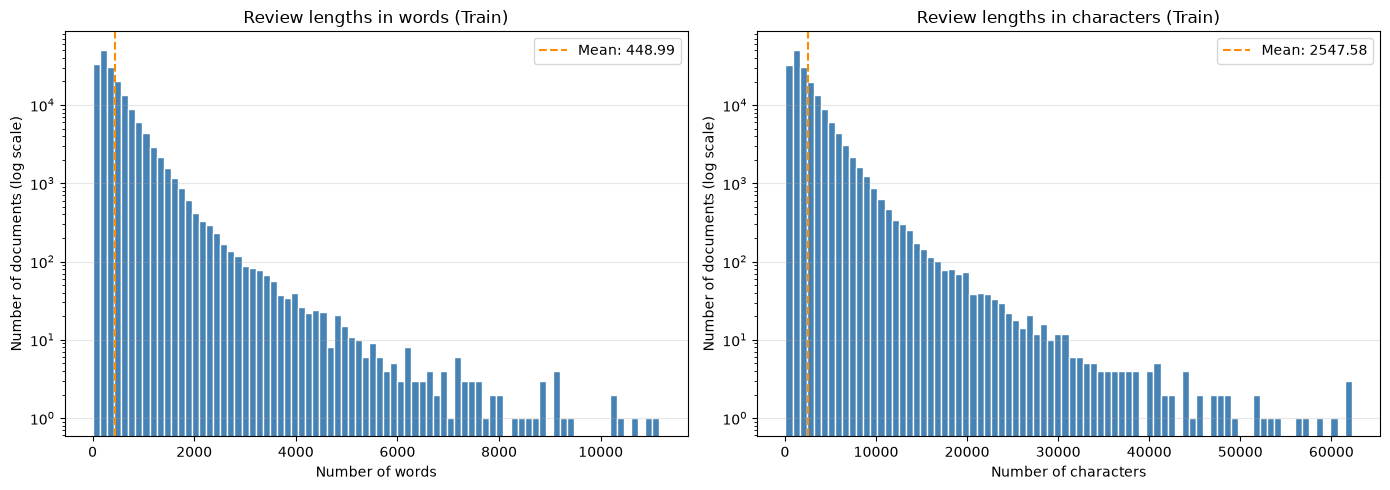

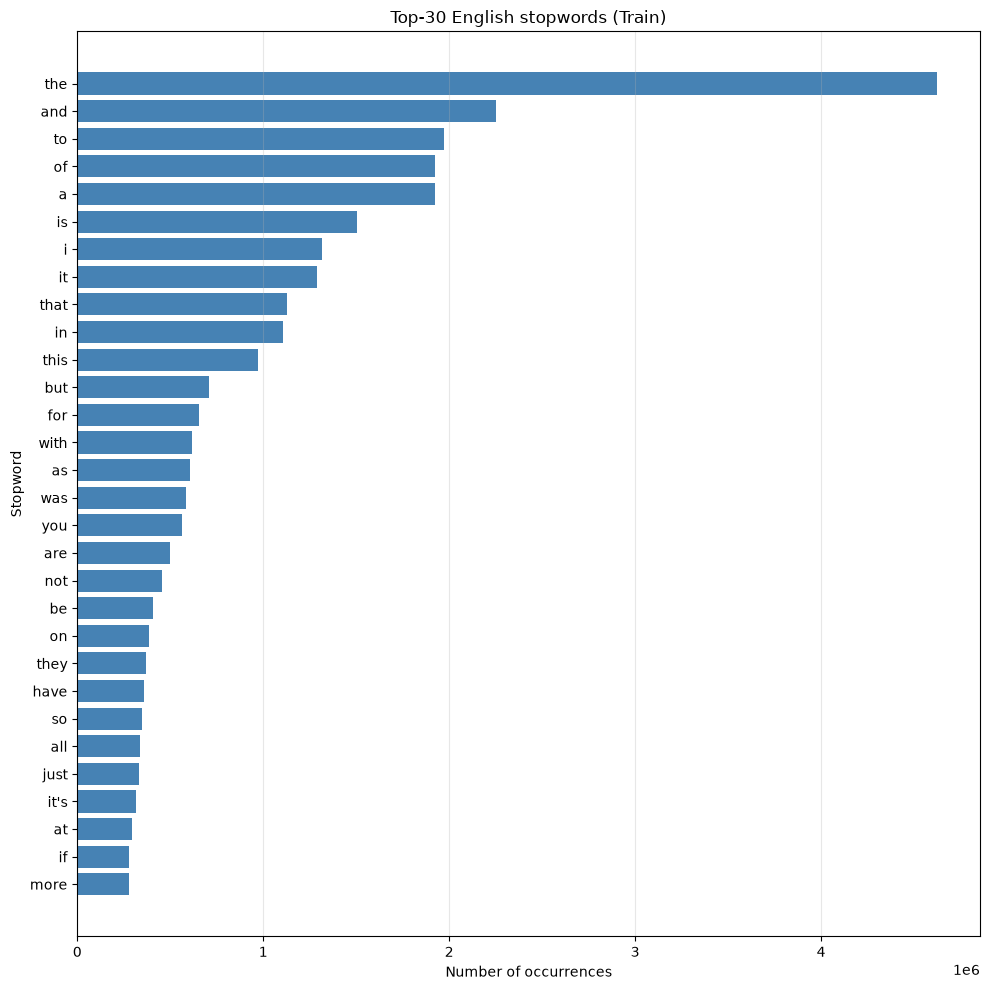

Investigation time: 33.62s


In [28]:
start_time = perf_counter()
investigate_df_regex(df_train, text_col='review')
# investigate_df(df_train, text_col='review')
print(f'Investigation time: {perf_counter() - start_time:.2f}s')


**Сравнение времени токенизации**

Сравниваем способы на одинаковой выборке из 1000 отзывов Train. Проверяем совпадение токенов и измеряем медиану времени трёх прогонов. Подсчёт частот и построение графиков в этот замер не входят.


In [29]:
benchmark_docs = df_train['review'].sample(n=1000, random_state=RANDOM_STATE)
benchmark_word_pattern = (r"[\p{L}\p{N}][\p{L}\p{M}\p{N}]*"
                          r"(?:['’][\p{L}\p{N}][\p{L}\p{M}\p{N}]*)*")
benchmark_flags = regex.UNICODE | regex.MULTILINE | regex.DOTALL
benchmark_pattern = regex.compile(benchmark_word_pattern, flags=benchmark_flags)
benchmark_nltk_tokenizer = nltk.tokenize.RegexpTokenizer(benchmark_word_pattern)

# Контрольный поиск с таймером показывает расходы проверки времени, используемой в NLTK.
benchmark_tokenizers = {
    'regex, no timeout, concurrent=False': lambda s: benchmark_pattern.findall(s, concurrent=False),
    'regex, no timeout, default concurrent': benchmark_pattern.findall,
    'regex, timeout=5, default concurrent': lambda s: benchmark_pattern.findall(s, timeout=5),
    'RegexpTokenizer, one instance': benchmark_nltk_tokenizer.tokenize,
    'regexp_tokenize': lambda s: regexp_tokenize(s, benchmark_word_pattern)
}

# Проверяем не только длины, но и полное совпадение списков токенов.
benchmark_cases = {'cafe\u0301': ['cafe\u0301'], 'q\u0301abc': ['q\u0301abc'],
                   '❤️': [], '_____': [], 'foo❤️bar': ['foo', 'bar'], "don't": ["don't"]}
for tokenize in benchmark_tokenizers.values():
    for s, expected in benchmark_cases.items():
        assert tokenize(s) == expected
for s in benchmark_docs:
    expected = benchmark_pattern.findall(s, concurrent=False)
    for tokenize in benchmark_tokenizers.values():
        assert tokenize(s) == expected

benchmark_results = []
for name, tokenize in benchmark_tokenizers.items():
    elapsed_times = []
    for _ in range(3):
        start_time = perf_counter()
        num_tokens = sum(len(tokenize(s)) for s in benchmark_docs)
        elapsed_times.append(perf_counter() - start_time)
    benchmark_results.append({'Tokenizer': name, 'Median time, s': np.median(elapsed_times), 'Tokens': num_tokens})

benchmark_df = pd.DataFrame(benchmark_results).set_index('Tokenizer')
benchmark_df['Relative time'] = benchmark_df['Median time, s'] / benchmark_df['Median time, s'].iloc[0]
benchmark_df.round({'Median time, s': 4, 'Relative time': 2})


,"Median time, s",Tokens,Relative time
Tokenizer,,,
"regex, no timeout, concurrent=False",0.0936,439199,1.00
"regex, no timeout, default concurrent",0.1271,439199,1.36
"regex, timeout=5, default concurrent",0.4906,439199,5.24
"RegexpTokenizer, one instance",0.5060,439199,5.41
regexp_tokenize,0.5322,439199,5.69


Оба способа дают одинаковые токены. Для исследования выбран прямой вызов `regex`, показавший меньшее время выполнения.


Оба распределения имеют выраженный правый хвост: короткие отзывы встречаются часто, очень длинные — редко. Длинные тексты увеличивают среднее. Среди частых стоп-слов есть отрицание `not`, существенное для передачи отношения автора; при очистке его следует сохранить.


---

## 3.

> Проанализируйте текст и выявите не менее 3 типов специфического шума, характерного для вашего домена (например: HTML-теги, URL-адреса, Twitter-ники вроде @username, технические логи, шестнадцатеричные символы, смайлики или спецсимволы). Шума может и не быть в датасете, докажите это.

Исследуем отзывы Train до очистки. Для каждого типа шума считаем количество документов, их долю в выборке и число вхождений. Один отзыв может содержать несколько типов шума.

- **HTML-сущности** (`&quot;`, `&amp;`, `&rsquo;`): закодированные кавычки, апострофы и другие символы.
- **URL-адреса**: ссылки на блоги, изображения и внешние материалы.
- **Вставка с многоточием и отступами**: перенос строки, не менее пяти пробелов или табуляций, `...`, ещё один перенос и большой отступ. Повторяемость этой конструкции внутри предложений указывает на вероятный артефакт извлечения текста. Обычные многоточия правило не затрагивает.
- **Необычные пробелы и невидимые символы**: неразрывный пробел, zero-width space, метки направления, word joiner и BOM.
- **HTML-теги**: остатки разметки форматирования.
- **BBCode-теги**: пользовательская разметка вроде `[b]`, `[i]`, `[spoiler]`.

Детекторы эвристические: они покрывают перечисленные конструкции, а не все возможные варианты разметки и ссылок.


In [26]:
# У атрибута требуем явное значение: текст вроде <I don't really write...> не является тегом.
# Необязательное многоточие учитывает найденную вставку с отступами внутри одного тега img.
html_attribute_pattern = r"""\s+(?:\.\.\.\s+)?[A-Za-z_:][\w:.-]*\s*=\s*(?:"[^"]*"|'[^']*'|[^\s<>"'=]+)"""

noise_patterns = {
    'HTML-сущности': re.compile(r'&(?:#[0-9]+|#[xX][0-9A-Fa-f]+|[A-Za-z][A-Za-z0-9]+);'),
    # После www. требуем домен и суффикс: название WWW.Working!! не является ссылкой
    'URL-адреса': re.compile(r"\b(?:https?://[^\s<>\"']+|www\.(?:[A-Za-z0-9-]+\.)+[A-Za-z]{2,}(?:[/:?#][^\s<>\"']*)?)", re.IGNORECASE),
    'Вставка с многоточием и отступами': review_ui_pattern,
    'Необычные пробелы и невидимые символы': re.compile(r'[\u00a0\u200b\u200e\u200f\u2060\ufeff]'),
    'HTML-теги': re.compile(rf'</?(?:a|b|i|u|p|br|div|span|strong|em|blockquote|img)(?:{html_attribute_pattern})*\s*/?>', re.IGNORECASE),
    'BBCode-теги': re.compile(r'\[/?(?:b|i|u|s|url|img|quote|spoiler|color|size)(?:=[^\]\r\n]*)?\]', re.IGNORECASE)
}

In [31]:
# Для каждого типа шума храним частоты совпадений и два контекстных примера.
docs: pd.Series = df_train['review']
noise_stats = []
noise_examples = {}
noise_counters = {}

#============================================================

# Считаем документы с шумом и общее число его вхождений в Train.
for noise_type, pattern in noise_patterns.items():
    num_docs = 0
    noise_examples[noise_type] = []
    noise_counters[noise_type] = Counter()
    
    for doc_idx, s in docs.items():
        matches = list(pattern.finditer(s))
        if not matches:
            continue
        
        num_docs += 1
        noise_counters[noise_type].update(match.group() for match in matches)
        
        # Два примера из разных документов с сохранением исходного индекса
        if len(noise_examples[noise_type]) < 2:
            match = matches[0]
            context = s[max(0, match.start() - 60):match.end() + 60]
            noise_examples[noise_type].append((doc_idx, match.group(), context))
    
    noise_stats.append({
        'Noise type': noise_type,
        'Documents': num_docs,
        'Documents, %': 100 * num_docs / docs.shape[0],
        'Occurrences': noise_counters[noise_type].total()
    })

#============================================================

# Сводим результаты в таблицу и сортируем по числу затронутых документов.
noise_stats_df = pd.DataFrame(noise_stats).set_index('Noise type')
noise_stats_df = noise_stats_df.sort_values('Documents', ascending=False)
noise_stats_df.round({'Documents, %': 3})

,Documents,"Documents, %",Occurrences
Noise type,,,
Вставка с многоточием и отступами,170575,95.306,170575
HTML-сущности,2017,1.127,14032
URL-адреса,1159,0.648,1444
Необычные пробелы и невидимые символы,1081,0.604,8977
BBCode-теги,297,0.166,864
HTML-теги,16,0.009,73


Для каждого типа выводим три частых совпадения и два контекстных примера. `repr` делает видимыми переносы строк и специальные символы; индекс позволяет открыть полный отзыв.


In [32]:
# Каждый тип шума выводим отдельным блоком: частоты, затем два примера.
for noise_type in noise_patterns:
    print('\n' + '=' * 88)
    print(noise_type)
    print('=' * 88)
    print('\nТри наиболее частых совпадения:')
    for fragment, count in noise_counters[noise_type].most_common(3):
        print(f'  {fragment!r} — {count}')

    for example_num, (doc_idx, fragment, context) in enumerate(noise_examples[noise_type], start=1):
        print(f'\nПример {example_num} | индекс отзыва: {doc_idx}')
        print('-' * 88)
        print(f'Совпадение: {fragment!r}')
        print(f'Контекст:   {context!r}')



HTML-сущности

Три наиболее частых совпадения:
  '&quot;' — 6454
  '&rsquo;' — 4634
  '&rdquo;' — 584

Пример 1 | индекс отзыва: 163651
----------------------------------------------------------------------------------------
Совпадение: '&quot;'
Контекст:   'rest of the characters, like Naruse who automatically falls &quot;in-love&quot; for Keita and spends the entire series fawning'

Пример 2 | индекс отзыва: 136753
----------------------------------------------------------------------------------------
Совпадение: '&rsquo;'
Контекст:   'ing the lead female role cemented this on my watch list.  It&rsquo;s also interesting to note that Myself:Yourself has 2 male l'

URL-адреса

Три наиболее частых совпадения:
  'http://animefiend.blogspot.com' — 15
  'https://writtenandwriting.wordpress.com/' — 13
  'www.thenextthingblog.wordpress.com' — 10

Пример 1 | индекс отзыва: 146792
----------------------------------------------------------------------------------------
Совпадение: 'http://img

In [33]:
# print(df_train.loc[56588, 'review'])

Служебная вставка с многоточием встречается массово, HTML-теги — редко. Вставка обнаружена даже внутри тега `img`, поэтому её нужно учитывать при распознавании разметки.

`WWW.Working!!` — название аниме, `<I=I>` — ASCII-смайлик, `<I don't really write that many reviews>` — авторская фраза. Для исключения таких срабатываний URL-шаблон требует домен с суффиксом, а атрибуты HTML — конструкцию `имя=значение`.

При очистке HTML-сущности следует декодировать, а у форматирующей разметки удалять теги, сохраняя содержимое. URL-детектор может захватить прилегающую пунктуацию — её нужно сохранить при замене ссылки. Числа, оценки `8/10`, названия и выразительную пунктуацию сами по себе шумом не считаем.


**Структурные шумы отзывов**

Языковой отбор и удаление технических дубликатов выполнены до разбиения. Здесь ищем оставшиеся конструкции, не изменяя `review`.

- **Добивка повторяющимся хвостом:** не менее восьми одинаковых токенов в конце отзыва и дополнительный признак: фраза об увеличении объёма; плейсхолдер `word`, `words`, `content`, `filler`, `blah`; одна буква, повторённая не менее 20 раз; токен из пяти и более букв `a`, `s`, `d`; либо весь документ состоит из одного повторяемого слова. `filler_candidate=True` помечает такой хвост для удаления в задании 4. Повтор `SPOILER` и хвосты без этих признаков сохраняем.
- **Известная копипаста:** начало сценария Bee Movie и ещё две характерные фразы в первых 1800 символах вставки.
- **Пустая форма:** после исключения известных вопросов и инструкций не остаётся другого текста. Ответы, смайлики и нераспознанный остаток означают, что блок сохраняется.
- **Декоративный разделитель:** отдельная строка из восьми и более символов `-`, `_`, `=`, `*`, `~`, `─`, `━`. Удалению подлежит строка, а не отзыв.
- **Ошибочное декодирование (mojibake):** последовательности вроде `â€™` и `Ã©`, характерные для повреждённого представления символов.

Авторские подписи и саморекламу сохраняем.


In [27]:
# Фразы об ограничении объёма и намеренной добивке; ищем их в тексте перед повторяющимся хвостом.
filler_cue_pattern = re.compile(
    # Упоминания лимита слов или символов: word count, character limit, minimum words.
    r'\b(?:word|character)[ -]*(?:count|limit)\b|'
    r'\bminimum\s+(?:number\s+of\s+)?(?:words|characters)\b|'
    # Стандартное сообщение формы о недостаточном объёме отзыва.
    r'this\s+review\s+needs\s+more\s+information|'
    # Автор сообщает, что должен написать более длинный отзыв.
    r'\b(?:i\s+(?:have|need)\s+to|mal\s+wants\s+me\s+to)\s+write\s+(?:a\s+)?longer\s+review\b|'
    r'\breviews?\s+(?:have|has)\s+to\s+be\s+longer\b|'
    r'\b(?:this|it)\s+(?:review\s+)?needs?\s+to\s+be\s+(?:a\s+)?longer\b|'
    # Прямое объявление добивки: here is filler / here is some fluff.
    r"\bhere(?:['’]s|\s+is)\s+(?:some\s+)?(?:filler|fluff)\b|"
    # Просьба добавить текст или объявление повторения одного слова.
    r'\bneed\s+more\s+information\b|'
    r'\btime\s+to\s+spam\s+(?:one|a)\s+word\b|'
    # Вариант фразы: сайт снова просит увеличить объём отзыва.
    r'\b(?:keeps\s+)?asking\s+me\s+to\s+write\s+(?:a\s+)?longer\s+review\b', re.IGNORECASE
)

# Начало скопированной формы и начало известной вставки Bee Movie.
form_prompt_pattern = re.compile(r'this\s+review\s+needs\s+more\s+information[!.]?', re.IGNORECASE)
bee_opening_pattern = re.compile(r'\baccording\s+to\s+all\s+known\s+laws\s+of\s+aviation\b', re.IGNORECASE)

#============================================================

# Отдельные строки-разделители и характерные следы ошибочного декодирования.
structure_patterns = {
    'Декоративные строки-разделители': re.compile(r'^[ \t]*[-=_*~─━]{8,}[ \t]*\r?$', re.MULTILINE),
    'Сигнатуры mojibake': re.compile(r'â(?:€™|€œ|€\x9d|€“|€”|€¦|€˜)|Ã[\u0080-\u00bf]|Â[\u0080-\u00bf]|ðŸ')
}

#============================================================

# Известные тексты формы: вопросы и инструкции, а не произвольные предложения автора
form_template_texts = [
    'This review needs more information!',
    'Here are a few ideas of what you may want to include:',
    'Is the story unique? If it was predictable, did you enjoy it anyway because you like this genre/set-up?',
    'Do you think the art style is fitting for the story?',
    'Were the characters well-rounded? Did they have flaws and strengths, or were they unusually strong/smart/stupid?',
    'Did the characters react to situations and events in a realistic way?',
    "Do you think others will enjoy/dislike this series, even if you didn't? Why?",
    'Tips for New Writers',
    'Your first 105 words will be visible above the read more: Make them interesting!',
    'The best reviews use pronouns (I, me, my, you) very rarely.',
    'Avoid unnecessary openers: “This is my first review, please forgive any mistakes.”',
    'You can describe what the work is about, but keep in mind that readers have already seen the synopsis.',
    'Leave an extra line between paragraphs for easier reading.',
    'Need help deciding what information to include in your review? See this post for some ideas.'
]


# Приводим подсказки к тому же виду, в котором будем сравнивать текст отзыва.
form_template_views = [comparison_view(s) for s in form_template_texts]


#============================================================

# Поиск повторяющегося хвоста и проверка признаков добивки.
def find_repeated_tail(s, min_repeats=8):
    """
    Возвращает границы хвоста и признаки добивки; исходный текст не меняет.

    Если повторов меньше min_repeats, возвращает None.
    """
    # Пропускаем завершающие пробелы и пунктуацию, чтобы найти последний токен.
    pos = len(s)
    while pos > 0 and (s[pos - 1].isspace() or s[pos - 1] in '.,!?:;"\')]}'):
        pos -= 1
    tail_end = pos
    repeated_token = None
    repeats = 0
    tail_start = pos
    
    # Идём справа налево и считаем одинаковые токены, разделённые пробельными символами.
    while pos > 0:
        # Выделяем токен: буквы, цифры, подчёркивания и апострофы.
        token_end = pos
        while pos > 0 and (s[pos - 1].isalnum() or s[pos - 1] in "_'’"):
            pos -= 1
        if pos == token_end:
            break

        # Регистр не учитываем; при первом отличающемся токене хвост заканчивается.
        token = s[pos:token_end].casefold()
        if repeated_token is None:
            repeated_token = token
        elif token != repeated_token:
            break
        repeats += 1
        tail_start = pos

        # Между повторами допускаем пробелы и переносы строк, но не пунктуацию.
        before_spaces = pos
        while pos > 0 and s[pos - 1].isspace():
            pos -= 1
        if pos == before_spaces:
            break
    
    # Короткие повторы не проходят общий порог и дальше не классифицируются.
    if repeats < min_repeats:
        return None

    # Дополнительные признаки: фраза об увеличении объёма перед хвостом или слово-плейсхолдер.
    cue = filler_cue_pattern.search(comparison_view(s[:tail_start]))
    placeholder = repeated_token in {'word', 'words', 'content', 'filler', 'blah'}

    # Правила проверяются по приоритету: разделители и SPOILER не считаем добивкой.
    # Для остальных хвостов достаточно одного из перечисленных признаков добивки.
    # filler_candidate=True помечает хвост для удаления в задании 4; иначе его сохраняем.
    filler_candidate = False
    if not any(char.isalnum() for char in repeated_token):
        status = 'Разделители: учтены отдельным правилом'
    elif repeated_token in {'spoiler', 'spoilers'}:
        status = 'Предупреждение о спойлерах: сохраняем'
    elif cue is not None:
        filler_candidate = True
        status = 'Кандидат на добивку: явный маркер объёма'
    elif placeholder:
        filler_candidate = True
        status = 'Кандидат на добивку: повтор плейсхолдера'
    elif len(repeated_token) == 1 and repeated_token.isalpha() and repeats >= 20:
        # Для повторов одной буквы используем более строгий порог: 20 вместо 8.
        filler_candidate = True
        status = 'Кандидат на добивку: однобуквенный хвост'
    elif re.fullmatch(r'[asd]{5,}', repeated_token):
        # Клавиатурный набор: токен длиной от пяти символов из соседних клавиш a, s, d.
        filler_candidate = True
        status = 'Кандидат на добивку: клавиатурная последовательность'
    elif len(set(re.findall(r"[^\W_]+(?:['’][^\W_]+)*", comparison_view(s)))) == 1:
        # Вырожденный случай: во всём документе повторяется только один вид слова.
        filler_candidate = True
        status = 'Кандидат: однотокенный повтор вместо документа'
    else:
        status = 'Нет формальных признаков добивки: сохраняем'

    # start и end задают срез s[start:end]; cue хранит найденную фразу о добивке.
    return {'token': repeated_token, 'repeats': repeats, 'start': tail_start,
            'end': tail_end, 'cue': None if cue is None else cue.group(),
            'filler_candidate': filler_candidate, 'status': status}


def inspect_form_block(s):
    """Находит подсказки формы и проверяет, остался ли кроме них авторский текст."""
    # Рассматриваем хвост от сообщения формы до конца отзыва.
    prompt = form_prompt_pattern.search(s)
    if prompt is None:
        return None

    # Сравниваем без различий в оформлении; исходную строку не изменяем.
    block = comparison_view(s[prompt.start():])
    residual = block

    # Исключаем только известные вопросы и инструкции формы.
    for template in form_template_views:
        residual = residual.replace(template, ' ')

    # Дополнительные слова, ответы, смайлики и неполные шаблоны сохраняем
    is_empty = not residual.strip(' \t\r\n-_=*')
    return {'start': prompt.start(), 'is_empty': is_empty, 'residual': residual.strip()}


def find_known_copypasta(s):
    """Возвращает начало вставки Bee Movie при совпадении трёх известных фраз."""
    # Сначала ищем начало сценария, затем проверяем две дополнительные фразы.
    opening = bee_opening_pattern.search(s)
    if opening is None:
        return None

    # Проверяем первые 1800 символов вставки, устранив различия в оформлении.
    fragment = comparison_view(s[opening.start():opening.start() + 1800])
    signatures = ['according to all known laws of aviation',
                  'there is no way a bee should be able to fly',
                  'its wings are too small to get its fat little body off the ground']
    if all(signature in fragment for signature in signatures):
        return opening
    return None

In [35]:
# Собираем результаты детекторов: один отзыв может дать несколько типов наблюдений.
structure_observations = []

#============================================================

# Проверяем каждый отзыв Train, не изменяя его текст.
for doc_idx, s in df_train['review'].items():
    # Накапливаем находки текущего отзыва: тип, результат, пример и число вхождений.
    findings = []
    
    # Декоративные строки и mojibake: считаем все совпадения, показываем контекст первого.
    for noise_type, pattern in structure_patterns.items():
        matches = list(pattern.finditer(s))
        if matches:
            match = matches[0]
            context = s[max(0, match.start() - 60):match.end() + 100]
            findings.append((noise_type, 'Совпадение по структурному шаблону', repr(context), len(matches)))
    
    # Фиксируем результат проверки хвоста: добивка или повтор, который нужно сохранить.
    tail = find_repeated_tail(s)
    if tail:
        status = tail['status']
        evidence = (f"Токен: {tail['token']!r}\n"
                    f"Повторений: {tail['repeats']}\n"
                    f"Маркер добивки: {tail['cue']!r}\n"
                    f"Фрагмент хвоста: {s[tail['start']:tail['end']][:100]!r}")
        findings.append(('Повторы в конце отзыва', status, evidence, 1))
    
    # Различаем пустой шаблон формы и блок, в котором есть ответы или другой текст.
    form = inspect_form_block(s)
    if form:
        status = 'Пустой известный шаблон' if form['is_empty'] else 'Непустой или неполный шаблон: сохраняем'
        evidence = repr(s[form['start']:form['start'] + 220])
        findings.append(('Подсказки формы', status, evidence, 1))
    
    # Известную копипасту учитываем только при совпадении всех трёх сигнатур.
    copypasta = find_known_copypasta(s)
    if copypasta:
        evidence = repr(s[copypasta.start():copypasta.start() + 220])
        findings.append(('Известная копипаста', 'Совпали три сигнатуры Bee Movie', evidence, 1))
    
    # Переносим находки в общую таблицу вместе с исходным индексом отзыва.
    for noise_type, status, evidence, num_occurrences in findings:
        structure_observations.append({'Review index': doc_idx, 'Type': noise_type,
                                       'Status': status, 'Evidence': evidence, 'Occurrences': num_occurrences})

#============================================================

# Сводка по типу и результату: число отзывов, число вхождений и доля от Train.
structure_observations_df = pd.DataFrame(structure_observations)
structure_stats_df = structure_observations_df.groupby(['Type', 'Status']).agg(
    Documents=('Review index', 'nunique'),
    Occurrences=('Occurrences', 'sum')
)
structure_stats_df['Documents, %'] = 100 * structure_stats_df['Documents'] / len(df_train)
structure_stats_df.round({'Documents, %': 3})

Documents  \
Type                            Status                                                          
Декоративные строки-разделители Совпадение по структурному шаблону                       1784   
Известная копипаста             Совпали три сигнатуры Bee Movie                             5   
Повторы в конце отзыва          Кандидат на добивку: клавиатурная последователь...          1   
                                Кандидат на добивку: однобуквенный хвост                    2   
                                Кандидат на добивку: повтор плейсхолдера                    3   
                                Кандидат на добивку: явный маркер объёма                   10   
                                Кандидат: однотокенный повтор вместо документа              1   
                                Нет формальных признаков добивки: сохраняем                 1   
                                Предупреждение о спойлерах: сохраняем                       1   
                                Разделители: учтены отдельным правилом                      1   
Подсказки формы                 Непустой или неполный шаблон: сохраняем                    18   
                                Пустой известный шаблон                                     8   
Сигнатуры mojibake              Совпадение по структурному шаблону                          1   

                                                                                    Occurrences  \
Type                            Status                                                            
Декоративные строки-разделители Совпадение по структурному шаблону                         4664   
Известная копипаста             Совпали три сигнатуры Bee Movie                               5   
Повторы в конце отзыва          Кандидат на добивку: клавиатурная последователь...            1   
                                Кандидат на добивку: однобуквенный хвост                      2   
                                Кандидат на добивку: повтор плейсхолдера                      3   
                                Кандидат на добивку: явный маркер объёма                     10   
                                Кандидат: однотокенный повтор вместо документа                1   
                                Нет формальных признаков добивки: сохраняем                   1   
                                Предупреждение о спойлерах: сохраняем                         1   
                                Разделители: учтены отдельным правилом                        1   
Подсказки формы                 Непустой или неполный шаблон: сохраняем                      18   
                                Пустой известный шаблон                                       8   
Сигнатуры mojibake              Совпадение по структурному шаблону                            4   

                                                                                    Documents, %  
Type                            Status                                                            
Декоративные строки-разделители Совпадение по структурному шаблону                         0.997  
Известная копипаста             Совпали три сигнатуры Bee Movie                            0.003  
Повторы в конце отзыва          Кандидат на добивку: клавиатурная последователь...         0.001  
                                Кандидат на добивку: однобуквенный хвост                   0.001  
                                Кандидат на добивку: повтор плейсхолдера                   0.002  
                                Кандидат на добивку: явный маркер объёма                   0.006  
                                Кандидат: однотокенный повтор вместо документа             0.001  
                                Нет формальных признаков добивки: сохраняем                0.001  
                                Предупреждение о спойлерах: сохраняем                      0.001  
                                Разделители: учтены о

In [36]:
# Выбираем по два примера для каждой пары «тип шума — результат детектора».
structure_examples_df = structure_observations_df.groupby(['Type', 'Status'], sort=False).head(2)

#============================================================

# Примеры одного типа и результата выводим рядом, отдельным блоком.
for (noise_type, status), examples in structure_examples_df.groupby(['Type', 'Status'], sort=False):
    print('\n' + '=' * 88)
    print(noise_type)
    print(f'Результат: {status}')
    print('=' * 88)

    for example_num, (doc_idx, evidence) in enumerate(
        examples[['Review index', 'Evidence']].itertuples(index=False, name=None), start=1
    ):
        print(f'\nПример {example_num} | индекс отзыва: {doc_idx}')
        print('-' * 88)
        print(evidence)

#============================================================

# Отдельно показываем контрольные примеры добивки, формы и известной копипасты.
print('\n' + '=' * 88)
print('Контрольные примеры')
print('=' * 88)
structure_observations_df[structure_observations_df['Review index'].isin([183261, 81849, 81214, 56175, 212150])]



Декоративные строки-разделители
Результат: Совпадение по структурному шаблону

Пример 1 | индекс отзыва: 209773
----------------------------------------------------------------------------------------
"r plot (i know that's not why you're watching but still). \r\n------------------------------------------------------------------------------------------------------------------------\r\nSchool Days is about stock animu gurls getting manipulated by the main character and he dates them "

Пример 2 | индекс отзыва: 147350
----------------------------------------------------------------------------------------
'eric main characters and leave, it will get spoilery. \r\n\r\n\r\n----------------------------------------------------------------------------------\r\n\r\nWHAT?!!!!!?!\r\n\r\n\r\n\r\nTHE?!?!!!!!\r\n\r\n\r\n\r\n\r\nEVERLOVING?!!!!!?!!??!!!\r\n\r\n\r\n\r\n\r\n\r\nSON OF A CRIPPLED AF'

Повторы в конце отзыва
Результат: Кандидат на добивку: явный маркер объёма

Пример 1 | индекс отзыва

,Review index,Type,Status,Evidence,Occurrences
73,56175,Подсказки формы,Пустой известный шаблон,'This review needs more information!\r\nHere a...,1
485,212150,Известная копипаста,Совпали три сигнатуры Bee Movie,"'According to all known laws\r\nof aviation,\r...",1
987,81849,Повторы в конце отзыва,Кандидат на добивку: явный маркер объёма,Токен: 'word'\nПовторений: 84\nМаркер добивки:...,1
988,81849,Подсказки формы,Непустой или неполный шаблон: сохраняем,'This review needs more information!\r\nHere a...,1
1412,81214,Подсказки формы,Непустой или неполный шаблон: сохраняем,'This review needs more information! So Ill pu...,1


По выбранным признакам добивки выделено 17 хвостов. Повтор предупреждения о спойлерах и повтор без признаков добивки сохраняются. Обнаружены 8 пустых форм; ещё 18 блоков содержат дополнительный текст или неполный шаблон и сохраняются.

Mojibake найден в одном отзыве, но в четырёх местах: три `â€™` и одно `â€˜`. В таблице `Documents` обозначает число отзывов, `Occurrences` — число вхождений.

Для очистки важно учитывать, что служебная вставка может разрывать хвост или тег. После удаления добивки остаток может оказаться пустой формой. Эти зависимости определяют порядок правил конвейера в задании 4.


---

## 4.

> Напишите комплексный конвейер очистки текста, используя модуль re (Регулярные выражения). Запрещено просто удалять всё, кроме букв. Каждый тип шума должен обрабатываться своим правилом (например, URL-адреса должны заменяться на специальный токен `[URL]`, а числа — на токен `[NUM]`, либо аккуратно вырезаться, если они не несут смысла для вашей задачи). На выходе конвейера добавьте к каждому документу технические токены начала и конца последовательности: `<s>` и `</s>`.

Ссылки заменяем на `[URL]`; у разметки сохраняем текст. Декодируем HTML-сущности, исправляем найденные повреждения кодировки и приводим Unicode к NFC. Необычные пробелы заменяем обычными, служебные метки удаляем.

Удаляем декоративные строки, известный сценарный хвост Bee Movie, добивку по правилам задания 3 и пустые формы. Числа, оценки, отрицания, смайлики и авторские подписи сохраняем. Каждый текст обрамляем `<s>` и `</s>`; отзывы, полностью опустевшие после очистки, исключаем из очищенных выборок.


In [28]:
# Правила оформления: границы строк и невидимые символы.
unusual_spaces_pattern = re.compile(r'[\u00a0\u200b]')
invisible_marks_pattern = re.compile(r'[\u200e\u200f\u2060\ufeff]')
horizontal_spaces_pattern = re.compile(r'[ \t]+')
blank_lines_pattern = re.compile(r'\n{3,}')

# Блочные теги и границы ссылок заменяем пробелом; форматирующие теги убираем.
block_tag_pattern = re.compile(
    r'</?(?:br|p|div|blockquote|a|img)\b|\[/?(?:quote|url|img)\b', re.IGNORECASE
)


In [29]:
def replace_url(match):
    """Заменяет адрес, сохраняя прилегающую пунктуацию вне ссылки."""
    url = match.group()
    suffix = ''
    brackets = {')': '(', ']': '[', '}': '{'}

    # Отделяем пунктуацию справа; сбалансированные скобки считаем частью URL.
    while url:
        char = url[-1]
        is_outer_bracket = char in brackets and url.count(char) > url.count(brackets[char])
        if char in '.,!?;:’”' or is_outer_bracket:
            suffix = char + suffix
            url = url[:-1]
        else:
            break
    return '[URL]' + suffix


#============================================================

# URL в атрибутах разметки также сохраняем как специальный токен.
def replace_markup(match):
    """Убирает тег, сохраняя сведения о ссылке и границы текстовых блоков."""
    tag = match.group()
    if noise_patterns['URL-адреса'].search(tag):
        return ' [URL] '
    if block_tag_pattern.match(tag):
        return ' '
    return ''


In [30]:
def clean_review(s):
    """Очищает один отзыв по правилам задания 3 и добавляет границы документа."""
    # Сначала восстанавливаем символы и убираем служебную вставку внутри текста.
    s = review_ui_pattern.sub(' ', s)
    # Вложенные сущности вроде &amp;quot; декодируем до устойчивого результата.
    decoded = unescape(s)
    while decoded != s:
        s = decoded
        decoded = unescape(s)
    if structure_patterns['Сигнатуры mojibake'].search(s):
        s = fix_encoding(s)
    s = normalize('NFC', s)
    s = s.replace('\r\n', '\n').replace('\r', '\n')
    s = unusual_spaces_pattern.sub(' ', s)
    s = invisible_marks_pattern.sub('', s)

    # BBCode обрабатываем до появления [URL] из HTML: иначе токен похож на BBCode-тег.
    s = noise_patterns['BBCode-теги'].sub(replace_markup, s)
    s = noise_patterns['HTML-теги'].sub(replace_markup, s)
    s = noise_patterns['URL-адреса'].sub(replace_url, s)
    s = structure_patterns['Декоративные строки-разделители'].sub('', s)

    # Найденные в Train вставки Bee Movie продолжаются до конца отзыва.
    copypasta = find_known_copypasta(s)
    if copypasta:
        s = s[:copypasta.start()]

    # Снимаем добивку и пустую форму, пока они могут открывать друг друга в хвосте.
    previous = None
    while s != previous:
        previous = s
        tail = find_repeated_tail(s)
        if tail and tail['filler_candidate']:
            s = s[:tail['start']]
        form = inspect_form_block(s)
        if form and form['is_empty']:
            s = s[:form['start']]

    # Сохраняем абзацы, сокращая лишние пробелы и пустые строки.
    s = horizontal_spaces_pattern.sub(' ', s)
    s = blank_lines_pattern.sub('\n\n', s).strip()
    return f'<s> {s} </s>' if s else '<s> </s>'


In [31]:
# Одинаковая очистка для Train и Test; исходная колонка review остаётся доступной.
train_clean = df_train['review'].map(clean_review)
test_clean = df_test['review'].map(clean_review)

cleaning_stats_df = pd.DataFrame({
    'Before': [len(train_clean), len(test_clean)],
    'Empty after cleaning': [train_clean.eq('<s> </s>').sum(), test_clean.eq('<s> </s>').sum()]
}, index=['Train', 'Test'])
train_clean = train_clean[train_clean.ne('<s> </s>')]
test_clean = test_clean[test_clean.ne('<s> </s>')]
cleaning_stats_df['After'] = [len(train_clean), len(test_clean)]
cleaning_stats_df


,Before,Empty after cleaning,After
Train,178976,1,178975
Test,44745,0,44745


In [41]:
# Контрольные примеры: форма, добивка, кодировка и сохранённые ответы.
for doc_idx in [56175, 81849, 81214, 183058, 212150]:
    if doc_idx not in train_clean.index:
        continue
    print('\n' + '=' * 88)
    print(f'Индекс отзыва: {doc_idx}')
    print('=' * 88)
    print('До очистки (первые 350 символов):')
    print(repr(df_train.loc[doc_idx, 'review'][:350]))
    print('\nПосле очистки (первые 550 символов):')
    print(repr(train_clean.loc[doc_idx][:550]))



Индекс отзыва: 56175
До очистки (первые 350 символов):
'No romance, totally deserved this.\r\n\r\nThis review needs more information!\r\nHere are a few ideas of what you may want to include:\r\n\r\nIs the story unique? If it was predictable, did you enjoy it anyway because you like this genre/set-up?\r\nDo you think the art style is fitting for the story?\r\nWere the characters well-rounded? Did they have flaws and s'

После очистки (первые 550 символов):
'<s> No romance, totally deserved this. </s>'

Индекс отзыва: 81849
До очистки (первые 350 символов):
"its Trash but it's my trash \r\n\r\nThis review needs more information!\r\nHere are a few ideas of what you may want to include:\r\n\r\nword word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word word"

После очистки (первые 550 символов):
"<s> its Trash but it's my trash </s

In [42]:
# Проверяем остаточные совпадения в Train, исключая специальный токен [URL].
remaining_noise = {}
for noise_type, pattern in {**noise_patterns, **structure_patterns}.items():
    count = 0
    for s in train_clean:
        if noise_type == 'BBCode-теги':
            found = any(match.group() != '[URL]' for match in pattern.finditer(s))
        else:
            found = pattern.search(s) is not None
        count += found
    remaining_noise[noise_type] = count
pd.Series(remaining_noise, name='Documents after cleaning').to_frame()


,Documents after cleaning
HTML-сущности,2
URL-адреса,0
Вставка с многоточием и отступами,0
Необычные пробелы и невидимые символы,0
HTML-теги,0
BBCode-теги,0
Декоративные строки-разделители,0
Сигнатуры mojibake,0


Проверка подтверждает удаление найденной разметки, ссылок, служебных вставок и повреждений кодировки. Ответы в форме и сохраняемые повторы остаются в тексте.

Оставшиеся совпадения HTML-шаблона — строки вроде `&Kouta;`, не являющиеся известными HTML-сущностями. Они не декодируются и сохраняются как авторский текст.


---

## 5.

> Сравнительная нормализация: Проведите нормализацию текстов двумя способами: с помощью стемминга и с помощью лемматизации. Сравните размер полученных словарей (количества уникальных токенов) до и после каждого вида нормализации. Сделайте выводы о применимости каждого метода для вашего типа текстов.

Сравниваем словари слов на очищенном Train. Слова выделяем по правилу задания 2, регистр и варианты апострофа объединяем. Дополнительно выделяем каждый знак Unicode-пунктуации отдельным токеном. Апостроф внутри слова остаётся частью слова; остальные символы, включая эмодзи, не выделяем. Технические токены `<s>`, `</s>` и `[URL]` сохраняем.

В размер словаря слов не включаем пунктуацию и технические токены. `word_counts` хранит частоты словоформ; `token_counts` — частоты слов и пунктуации для языковой модели. Стоп-слова не удаляем.

На всём Train сравниваем `PorterStemmer` и `WordNetLemmatizer(pos='n')`. Дополнительное сравнение с POS-разметкой проводим ниже на общей фиксированной выборке Train.


In [32]:
# Сначала распознаём границы и ссылки, затем слова и отдельные знаки пунктуации.
# Внутренний апостроф входит в слово; \p{P} охватывает Unicode-пунктуацию.
special_tokens = {'<s>', '</s>', '[URL]'}
word_token_pattern = regex.compile(
    r"</?s>|\[URL\]|[\p{L}\p{N}][\p{L}\p{M}\p{N}]*"
    r"(?:['’][\p{L}\p{N}][\p{L}\p{M}\p{N}]*)*|\p{P}"
)


def tokenize_review(s):
    """Выделяет слова, пунктуацию и технические токены; объединяет регистр и апострофы."""
    tokens = word_token_pattern.findall(s, concurrent=False)
    return [token if token in special_tokens else token.lower().replace('’', "'")
            for token in tokens]


In [33]:
# Слова и пунктуацию считаем только по Train; технические токены не включаем.
word_counts = Counter()
token_counts = Counter()
for s in train_clean:
    tokens = [token for token in tokenize_review(s) if token not in special_tokens]
    token_counts.update(tokens)
    # По шаблону любой словесный токен начинается с буквы или числа.
    word_counts.update(token for token in tokens if token[0].isalnum())

print(f'Number of word tokens: {word_counts.total()}')
print(f'Vocabulary before normalization: {len(word_counts)}')
print(f'Number of punctuation tokens: {token_counts.total() - word_counts.total()}')


Number of word tokens: 80313519
Vocabulary before normalization: 229920
Number of punctuation tokens: 10908715


In [45]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Каждое уникальное слово преобразуем один раз; затем используем готовые соответствия.
stem_forms = {word: stemmer.stem(word) for word in word_counts}
lemma_forms = {word: lemmatizer.lemmatize(word, pos='n') for word in word_counts}

vocabulary_sizes_df = pd.DataFrame({
    'Vocabulary size': [len(word_counts), len(set(stem_forms.values())), len(set(lemma_forms.values()))]
}, index=['Before normalization', 'Porter stemming', "WordNet lemmatization (pos='n')"])
vocabulary_sizes_df['Reduction, %'] = 100 * (1 - vocabulary_sizes_df['Vocabulary size'] / len(word_counts))
vocabulary_sizes_df.round({'Reduction, %': 2})


,Vocabulary size,"Reduction, %"
Before normalization,229920,0.00
Porter stemming,176511,23.23
WordNet lemmatization (pos='n'),218323,5.04


In [46]:
# Нормализуем слова; пунктуацию, границы документов и ссылки сохраняем.
stemmed_texts = []
lemmatized_texts = []
for s in train_clean:
    tokens = tokenize_review(s)
    stemmed_texts.append(' '.join(stem_forms.get(token, token) for token in tokens))
    lemmatized_texts.append(' '.join(lemma_forms.get(token, token) for token in tokens))

train_stemmed = pd.Series(stemmed_texts, index=train_clean.index, name='stemmed')
train_lemmatized = pd.Series(lemmatized_texts, index=train_clean.index, name='lemmatized')
del stemmed_texts, lemmatized_texts

print('Stemming example:')
print(train_stemmed.iloc[0][:350])
print('\nLemmatization example:')
print(train_lemmatized.iloc[0][:350])


Stemming example:
<s> first , let me say thi . i am a ( 2 ) type . i feel i wrote too much about spoiler , so i may eras my review in a few day . as for the impress of those who have seen it , they are roughli divid into ( 3 ) pattern . ( 1 ) someon who ha never heard of sladan . " i don't understand the " stori . ( 2 ) peopl who like the episod of sladan . i don't 

Lemmatization example:
<s> first , let me say this . i am a ( 2 ) type . i feel i wrote too much about spoiler , so i may erase my review in a few day . a for the impression of those who have seen it , they are roughly divided into ( 3 ) pattern . ( 1 ) someone who ha never heard of sladan . " i don't understand the " story . ( 2 ) people who like the episode of sladan .


In [47]:
# Сопоставляем существительные и глагольные формы, встречающиеся в корпусе.
example_words = ['characters', 'stories', 'episodes', 'watching', 'watched',
                 'animation', 'emotional', 'recommended', 'better', 'has', 'as']
normalization_examples_df = pd.DataFrame([
    {'Word': word, 'Frequency': word_counts[word],
     'Stemming': stem_forms[word], 'Lemmatization': lemma_forms[word]}
    for word in example_words if word in word_counts
])
normalization_examples_df


,Word,Frequency,Stemming,Lemmatization
0,characters,407404,charact,character
1,stories,23771,stori,story
2,episodes,120467,episod,episode
3,watching,97035,watch,watching
4,watched,49411,watch,watched
5,animation,112371,anim,animation
6,emotional,21528,emot,emotional
7,recommended,4604,recommend,recommended
8,better,80535,better,better
9,has,222982,ha,ha


**Лемматизация с учётом части речи**

Для пяти методов используем одни и те же 5000 случайных отзывов Train. Размер этой выборки задаёт `NORMALIZATION_SAMPLE_SIZE`; её словари сравниваем между собой, отдельно от словарей всего Train выше.

В NLTK получаем Penn Treebank-теги через `nltk.pos_tag()`, переводим их функцией `wordnet.tag2pos()` и передаём в WordNet. Если WordNet не поддерживает часть речи, слово сохраняем.

В spaCy используем `en_core_web_sm`: собственный POS-теггер и английский лемматизатор на правилах и словарных таблицах. Это отдельная реализация, не вызов лемматизатора NLTK. Передаём готовые токены через `Doc`, чтобы различия токенизации не влияли на сравнение. Оба метода видят контекст отзыва и пунктуацию; слова уже приведены к нижнему регистру.


In [48]:
NORMALIZATION_SAMPLE_SIZE = 5000
normalization_sample = train_clean.sample(
    n=min(NORMALIZATION_SAMPLE_SIZE, len(train_clean)), random_state=RANDOM_STATE
)

# Для лемматизации нужны POS-теги; синтаксический анализ и распознавание сущностей отключаем.
nlp = spacy.load('en_core_web_sm', exclude=['parser', 'ner'])
print(f'Documents in the common normalization sample: {len(normalization_sample)}')


Documents in the common normalization sample: 5000


In [49]:
def lemmatize_with_pos(tokens):
    """Лемматизирует последовательность по Penn Treebank-тегам NLTK и POS WordNet."""
    lemmas = []
    for token, tag in nltk.pos_tag(tokens, lang='eng'):
        pos = wordnet.tag2pos(tag)
        # Пунктуацию, ссылки и слова с неподдерживаемой частью речи сохраняем.
        if token[0].isalnum() and pos is not None:
            lemmas.append(lemmatizer.lemmatize(token, pos=pos))
        else:
            lemmas.append(token)
    return lemmas


In [50]:
# POS-разметку делаем в контексте каждого отзыва, а не по списку уникальных слов.
sample_word_counts = Counter()
pos_lemma_counts = Counter()
start_time = perf_counter()
for s in normalization_sample:
    tokens = tokenize_review(s)[1:-1]
    lemmas = lemmatize_with_pos(tokens)
    sample_word_counts.update(token for token in tokens if token[0].isalnum())
    pos_lemma_counts.update(lemma for token, lemma in zip(tokens, lemmas)
                            if token[0].isalnum())
print(f'WordNet with POS: {perf_counter() - start_time:.2f}s')


WordNet with POS: 54.15s


In [51]:
# Doc сохраняет нашу токенизацию; nlp.pipe обрабатывает отзывы пакетами.
spacy_lemma_counts = Counter()
sample_docs = (Doc(nlp.vocab, words=tokenize_review(s)[1:-1]) for s in normalization_sample)
start_time = perf_counter()
for doc in nlp.pipe(sample_docs, batch_size=64):
    spacy_lemma_counts.update(token.lemma_.lower().replace('’', "'") for token in doc
                              if token.text[0].isalnum())
print(f'spaCy with POS: {perf_counter() - start_time:.2f}s')


spaCy with POS: 142.55s


In [52]:
# Для базовых методов также берём только слова этой же выборки.
comparison_sizes = {
    'Before normalization': len(sample_word_counts),
    'Porter stemming': len({stem_forms[word] for word in sample_word_counts}),
    "WordNet (pos='n')": len({lemma_forms[word] for word in sample_word_counts}),
    'WordNet + NLTK POS': len(pos_lemma_counts),
    'spaCy + POS': len(spacy_lemma_counts)
}
pos_vocabulary_sizes_df = pd.DataFrame.from_dict(
    comparison_sizes, orient='index', columns=['Vocabulary size']
)
pos_vocabulary_sizes_df['Reduction, %'] = 100 * (
    1 - pos_vocabulary_sizes_df['Vocabulary size'] / len(sample_word_counts)
)
pos_vocabulary_sizes_df.round({'Reduction, %': 2})


,Vocabulary size,"Reduction, %"
Before normalization,42615,0.00
Porter stemming,29886,29.87
WordNet (pos='n'),38744,9.08
WordNet + NLTK POS,36313,14.79
spaCy + POS,35257,17.27


In [53]:
# Контрольные фразы показывают влияние части речи, включая два значения saw.
context_examples = [
    'The characters were watching the episodes.',
    'He has better stories, as a fan would expect.',
    'I saw the ending. The saw was sharp.'
]
context_rows = []
for sentence in context_examples:
    tokens = tokenize_review(sentence)
    tagged = nltk.pos_tag(tokens, lang='eng')
    pos_lemmas = lemmatize_with_pos(tokens)
    doc = nlp(Doc(nlp.vocab, words=tokens))
    for (token, tag), lemma, spacy_token in zip(tagged, pos_lemmas, doc):
        if token not in {'characters', 'were', 'watching', 'episodes', 'has', 'better',
                         'stories', 'as', 'saw'}:
            continue
        context_rows.append({
            'Context': sentence, 'Word': token, 'Penn tag': tag,
            'WordNet POS': wordnet.tag2pos(tag),
            "WordNet (n)": lemmatizer.lemmatize(token, pos='n'),
            'WordNet + POS': lemma, 'spaCy POS': spacy_token.pos_,
            'spaCy lemma': spacy_token.lemma_.lower()
        })
pd.DataFrame(context_rows)


,Context,Word,Penn tag,WordNet POS,WordNet (n),WordNet + POS,spaCy POS,spaCy lemma
0,The characters were watching the episodes.,characters,NNS,n,character,character,NOUN,character
1,The characters were watching the episodes.,were,VBD,v,were,be,AUX,be
2,The characters were watching the episodes.,watching,VBG,v,watching,watch,VERB,watch
3,The characters were watching the episodes.,episodes,NNS,n,episode,episode,NOUN,episode
4,"He has better stories, as a fan would expect.",has,VBZ,v,ha,have,AUX,have
5,"He has better stories, as a fan would expect.",better,JJR,a,better,good,ADJ,well
6,"He has better stories, as a fan would expect.",stories,NNS,n,story,story,NOUN,story
7,"He has better stories, as a fan would expect.",as,IN,NaN,a,as,ADP,as
8,I saw the ending. The saw was sharp.,saw,VBD,v,saw,saw,VERB,see
9,I saw the ending. The saw was sharp.,saw,NN,n,saw,saw,NOUN,saw


На всём Train стемминг сократил словарь на 23,23%, а WordNet с `pos='n'` — на 5,04%. Стемминг объединяет формы, но создаёт основы вроде `charact` и `stori`. Допущение о существительных ограничивает WordNet: глагольные формы могут не меняться, а `has` и `as` ошибочно переходят в `ha` и `a`.

На общей выборке из 5000 отзывов сокращение составило 9,08% для WordNet без POS, 14,79% для WordNet с POS и 17,27% для spaCy. Оба варианта с POS преобразуют `watching` в `watch`, `has` в `have` и сохраняют `as`.

POS не устраняет всей неоднозначности: WordNet оставляет глагольное `saw`, а spaCy преобразует его в `see`. В сочетании `better stories` spaCy выдаёт `well` вместо ожидаемого `good`; WordNet в этом примере получает `good`. Поэтому размер словаря сам по себе не доказывает качество лемматизации. Для сохранения словарных форм полезен учёт части речи, однако имена, названия и разговорная речь требуют проверки на примерах.


---

## 6.

> Поиск опечаток через строковые метрики: Самостоятельно (без использования готовых библиотек вычисления расстояния) реализуйте алгоритм расчета расстояния Левенштейна. Оптимизируйте алгоритм по памяти. С его помощью найдите в корпусе примеры слов с расстоянием редактирования равным 1 или 2 (опечатки, разные формы одного слова) и выведите топ-10 пар, если такие опечатки существуют.

Расстояние Левенштейна — минимальное число вставок, удалений и замен символов; каждая операция стоит 1. Храним только предыдущую и текущую строки матрицы. Время работы — $O(mn)$, дополнительная память — $O(\min(m, n))$.


In [54]:
def levenshtein_distance(s1, s2):
    """Вычисляет точное расстояние Левенштейна с двумя строками матрицы."""
    # Столбцы соответствуют более короткой строке, чтобы уменьшить память.
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    previous = list(range(len(s1) + 1))

    for i, char2 in enumerate(s2, start=1):
        current = [i]
        for j, char1 in enumerate(s1, start=1):
            deletion = previous[j] + 1
            insertion = current[j - 1] + 1
            substitution = previous[j - 1] + (char1 != char2)
            current.append(min(deletion, insertion, substitution))
        previous = current

    return previous[-1]


In [55]:
# Примеры проверяют пустую строку, совпадение и разные операции редактирования.
distance_examples = [('', 'anime', 5), ('anime', 'anime', 0), ('cat', 'cats', 1),
                     ('cat', 'cut', 1), ('form', 'from', 2), ('kitten', 'sitting', 3)]
distance_examples_df = pd.DataFrame(distance_examples, columns=['Word 1', 'Word 2', 'Expected'])
distance_examples_df['Distance'] = [levenshtein_distance(a, b) for a, b, _ in distance_examples]
assert distance_examples_df['Expected'].equals(distance_examples_df['Distance'])
distance_examples_df


,Word 1,Word 2,Expected,Distance
0,,anime,5,5
1,anime,anime,0,0
2,cat,cats,1,1
3,cat,cut,1,1
4,form,from,2,2
5,kitten,sitting,3,3


Пары ищем в словаре Train **до** стемминга и лемматизации, чтобы сохранить различия словоформ. Рассматриваем буквенные слова длиной от трёх символов, исключив стоп-слова.

Для каждого расстояния выводим топ-10 пар по частоте более редкого слова; при равенстве — по сумме частот. Такой порядок выделяет пары, в которых оба слова достаточно распространены. Само расстояние не доказывает наличие опечатки: среди близких строк бывают разные словоформы и самостоятельные слова.


In [56]:
def find_close_pairs(counts, target_distance, top_n=10):
    """Находит самые частотные пары с заданным расстоянием Левенштейна."""
    words = sorted(counts, key=lambda word: (-counts[word], word))
    pairs = []

    for i, word in enumerate(words):
        # Дальше частота более редкого слова только уменьшается.
        # Если она уже ниже порога топа, ни одна оставшаяся пара в него не попадёт.
        if len(pairs) == top_n and counts[word] < pairs[-1]['Min frequency']:
            break

        # Каждую неупорядоченную пару проверяем один раз.
        for other in words[:i]:
            if abs(len(word) - len(other)) > target_distance:
                continue
            distance = levenshtein_distance(word, other)
            if distance == target_distance:
                pairs.append({'Word 1': other, 'Word 2': word, 'Distance': distance,
                              'Frequency 1': counts[other], 'Frequency 2': counts[word],
                              'Min frequency': counts[word]})

        # После каждого слова оставляем только лучшие пары с учётом равных частот.
        pairs.sort(key=lambda pair: (-pair['Min frequency'],
                                     -pair['Frequency 1'] - pair['Frequency 2'],
                                     pair['Word 1'], pair['Word 2']))
        pairs = pairs[:top_n]

    return pd.DataFrame(pairs, columns=['Word 1', 'Word 2', 'Distance',
                                       'Frequency 1', 'Frequency 2', 'Min frequency'])


In [57]:
# Не включаем технические токены, числа и стоп-слова в поиск близких слов.
english_stops = set(stopwords.words('english'))
search_word_counts = {word: count for word, count in word_counts.items()
                      if len(word) >= 3 and word.isalpha() and word not in english_stops}
print(f'Vocabulary for pair search: {len(search_word_counts)}')

pairs_distance_1 = find_close_pairs(search_word_counts, target_distance=1)
pairs_distance_1


Vocabulary for pair search: 200926


,Word 1,Word 2,Distance,Frequency 1,Frequency 2,Min frequency
0,characters,character,1,407404,278334,278334
1,episode,episodes,1,143306,120467,120467
2,way,say,1,131519,110048,110048
3,plot,lot,1,127464,100756,100756
4,like,life,1,385567,94118,94118
5,would,could,1,168037,92736,92736
6,would,world,1,168037,92536,92536
7,make,made,1,112095,87308,87308
8,think,thing,1,112341,77994,77994
9,things,thing,1,83925,77994,77994


In [58]:
pairs_distance_2 = find_close_pairs(search_word_counts, target_distance=2)
pairs_distance_2


,Word 1,Word 2,Distance,Frequency 1,Frequency 2,Min frequency
0,anime,time,2,547595,184533,184533
1,like,time,2,385567,184533,184533
2,art,get,2,151283,150888,150888
3,one,see,2,321766,118136,118136
4,get,see,2,150888,118136,118136
5,get,great,2,150888,117353,117353
6,like,make,2,385567,112095,112095
7,main,make,2,127220,112095,112095
8,see,say,2,118136,110048,110048
9,like,love,2,385567,109686,109686


На расстоянии 1 найдены словоформы `characters — character`, `episode — episodes`, `things — thing`. В топ также попадают самостоятельные слова: `like — life`, `plot — lot`. На расстоянии 2 встречается, например, `anime — time`. Метрика показывает близость написания; этих данных недостаточно для автоматического исправления слов.


---

## 7.

> Построение языковой модели: На основе очищенного и токенизированного текста обучающей выборки постройте статистическую \(N\)-граммную модель (\(N=2\) или \(N=3\)).Сформируйте явный словарь модели и предусмотрите обработку неизвестных слов из тестовой выборки с помощью специального токена `[UNK]`.

Обучаем модели на `train_clean` с токенизацией из задания 5. Используем исходные словоформы, чтобы сохранять грамматические формы при генерации. Пунктуация входит в последовательность отдельными токенами.

Словарь общий для всех N и строится только по Train. Слова с частотой меньше пяти заменяем на `[UNK]` при обучении и оценке; все встреченные в Train знаки пунктуации сохраняем. Токен `[URL]` сохраняем отдельно. `<s>` служит только контекстом, `</s>` входит в предсказываемый словарь.

Перед каждым документом добавляем `n−1` маркеров `<s>`, после него — один `</s>`. Переходы между разными отзывами не учитываем. При `n=1` контекст пустой; при `n=2` используется один предыдущий токен, при `n=3` — два.


In [34]:
class NGramModel:
    """Частотная N-граммная модель: контекст из n−1 ID и частоты следующего токена."""

    def __init__(self, n, vocabulary):
        if not isinstance(n, int) or n < 1:
            raise ValueError('n must be a positive integer')
        self.n = n

        # ID 0 — начало документа; остальные ID образуют предсказываемый словарь.
        reserved = ['<s>', '</s>', '[UNK]', '[URL]']
        self.vocabulary = reserved + sorted(set(vocabulary) - set(reserved))
        self.word_to_id = {word: i for i, word in enumerate(self.vocabulary)}
        self.vocab_size = len(self.vocabulary) - 1
        self.counts = defaultdict(Counter)
        self.context_totals = {}

    def encode(self, tokens):
        """Кодирует слова; границы документа добавляются отдельно в ngrams."""
        unk_id = self.word_to_id['[UNK]']
        return [self.word_to_id.get(word, unk_id) for word in tokens
                if word not in {'<s>', '</s>'}]

    def ngrams(self, tokens):
        """Возвращает N-граммы одного документа с начальными и конечной границами."""
        prefix = [self.word_to_id['<s>']] * (self.n - 1)
        ids = prefix + self.encode(tokens) + [self.word_to_id['</s>']]
        return zip(*(ids[i:] for i in range(self.n)))

    #============================================================

    def fit(self, documents):
        """Считает переходы по последовательностям токенов Train."""
        self.counts.clear()
        self.context_totals.clear()
        for tokens in documents:
            for ngram in self.ngrams(tokens):
                self.counts[ngram[:-1]][ngram[-1]] += 1

        # Число исходящих переходов — знаменатель условной вероятности.
        self.context_totals = {context: sum(row.values())
                               for context, row in self.counts.items()}
        return self

    def probability(self, word_id, context, alpha=0.0):
        """Вычисляет P(word_id | context) с аддитивным сглаживанием alpha."""
        if alpha < 0 or len(context) != self.n - 1:
            raise ValueError('alpha must be nonnegative; context must have n-1 IDs')
        if word_id == self.word_to_id['<s>']:
            return 0.0
        count = self.counts.get(context, {}).get(word_id, 0)
        total = self.context_totals.get(context, 0)
        denominator = total + alpha * self.vocab_size
        return (count + alpha) / denominator if denominator else 0.0


In [35]:
# Слова и пунктуация из очищенного Train; редкие слова заменяем на [UNK].
MIN_WORD_COUNT = 5
model_vocabulary = {token for token, count in token_counts.items()
                    if count >= MIN_WORD_COUNT or not token[0].isalnum()}
punctuation_vocabulary = {token for token in model_vocabulary if not token[0].isalnum()}

print(f'Original word types: {len(word_counts)}')
print(f'Word types retained: {len(model_vocabulary) - len(punctuation_vocabulary)}')
print(f'Punctuation types retained: {len(punctuation_vocabulary)}')
print(f'Train word tokens mapped to [UNK]: '
      f'{sum(count for word, count in word_counts.items() if word not in model_vocabulary)}')


Original word types: 229920
Word types retained: 73535
Punctuation types retained: 125
Train word tokens mapped to [UNK]: 238183


In [36]:
# Один класс обучаем при двух значениях n; документы токенизируем по одному.
models = {}
model_stats = []
for n in (2, 3):
    start_time = perf_counter()
    model = NGramModel(n=n, vocabulary=model_vocabulary)
    model.fit(tokenize_review(s) for s in train_clean)
    models[n] = model
    model_stats.append({
        'N': n, 'Vocabulary size': model.vocab_size,
        'Contexts': len(model.counts),
        'Distinct N-grams': sum(len(row) for row in model.counts.values()),
        'Train predictions': sum(model.context_totals.values())
    })
    print(f'N={n}: training time {perf_counter() - start_time:.2f}s')
model_stats_df = pd.DataFrame(model_stats).set_index('N')
model_stats_df


N=2: training time 125.06s


N=3: training time 198.31s


,Vocabulary size,Contexts,Distinct N-grams,Train predictions
N,,,,
2,73663,73663,5622376,91402654
3,73663,5618719,26565161,91402654


In [37]:
# Примеры наиболее частых продолжений двух контекстов.
transition_examples = []
for n, words in [(2, ('this',)), (3, ('this', 'anime'))]:
    model = models[n]
    context = tuple(model.word_to_id[word] for word in words)
    for word_id, count in model.counts[context].most_common(5):
        transition_examples.append({
            'N': n, 'Context': ' '.join(words),
            'Next token': model.vocabulary[word_id], 'Count': count,
            'MLE probability': model.probability(word_id, context)
        })
pd.DataFrame(transition_examples).round({'MLE probability': 4})


,N,Context,Next token,Count,MLE probability
0,2,this,anime,152313,0.1566
1,2,this,is,120963,0.1244
2,2,this,show,97847,0.1006
3,2,this,series,45294,0.0466
4,2,this,movie,24540,0.0252
5,3,this anime,is,29058,0.1908
6,3,this anime,.,19580,0.1286
7,3,this anime,",",13076,0.0858
8,3,this anime,was,7205,0.0473
9,3,this anime,has,5086,0.0334


**Interpolated Kneser–Ney**

Добавляем `nltk.lm.KneserNeyInterpolated` с фиксированным `discount=0.75`. Корпус повторно не обрабатываем: переводим ID готовых N-грамм в строки и суммируем их частоты по суффиксам для порядков от 1 до N. На каждом уровне сохраняется то же число предсказаний. Начальные `<s>` остаются только в контекстах, в конце документа учитывается один `</s>`.

В `Vocabulary` задаём наш `[UNK]`; `<s>` нужен для распознавания контекстов, но не входит в список предсказываемых токенов. Не используем `.fit()` и повторное выделение редких слов.


In [38]:
def to_ngram_counter(model):
    """Переносит готовые частоты в NLTK, восстанавливая младшие порядки по суффиксам."""
    counter = NgramCounter()
    for context, row in model.counts.items():
        words = tuple(model.vocabulary[word_id] for word_id in context)
        targets = {model.vocabulary[word_id]: count for word_id, count in row.items()}
        assert all(count > 0 for count in targets.values())
        counter.unigrams.update(targets)
        for order in range(2, model.n + 1):
            counter[order][words[-(order - 1):]].update(targets)

    # Каждый суффикс соответствует ровно одному исходному предсказанию.
    num_predictions = sum(model.context_totals.values())
    for order in range(1, model.n + 1):
        assert counter[order].N() == num_predictions
    return counter


In [39]:
@contextmanager
def cached_kn_statistics():
    """Временно использует сохранённое число положительных частот наших распределений."""
    original = lm_smoothing._count_values_gt_zero

    def positive_types(distribution):
        if hasattr(distribution, '_kn_positive_types'):
            return distribution._kn_positive_types
        return original(distribution)

    # Формулы NLTK не меняем; после блока восстанавливаем библиотечную функцию.
    lm_smoothing._count_values_gt_zero = positive_types
    try:
        yield
    finally:
        lm_smoothing._count_values_gt_zero = original


In [40]:
def cache_kn_statistics(kn_model):
    """Готовит статистику различных левых продолжений для неизменяемых частот NLTK."""
    counter = kn_model.counts
    continuations = defaultdict(Counter)
    for order in range(1, kn_model.order + 1):
        rows = [counter.unigrams] if order == 1 else counter[order].values()
        for row in rows:
            # Все сохранённые частоты положительны; N() также кэширует сумму строки.
            row._kn_positive_types = len(row)
            row.N()
        if order >= 2:
            # Каждый различный левый контекст добавляет единицу, независимо от частоты.
            for prefix, row in counter[order].items():
                continuations[prefix[1:]].update(row.keys())
    totals = {context: row.total() for context, row in continuations.items()}

    def continuation_counts(word, context=()):
        row = continuations.get(context, {})
        return row.get(word, 0), totals.get(context, 0)

    # Сверяем кэш с методом NLTK до замены статистического запроса.
    original = kn_model.estimator._continuation_counts
    contexts = [()] + ([('<s>',)] if kn_model.order > 2 else [])
    with cached_kn_statistics():
        for context in contexts:
            for word in ('[UNK]', '[URL]', '</s>'):
                assert continuation_counts(word, context) == original(word, context)
    kn_model.estimator._continuation_counts = continuation_counts
    kn_model.estimator.unigram_score = lru_cache(maxsize=None)(kn_model.estimator.unigram_score)


In [41]:
KN_DISCOUNT = 0.75
kn_models = {}
kn_count_stats = []
for n, model in models.items():
    start_time = perf_counter()
    counter = to_ngram_counter(model)
    # NLTK добавляет unk_label сам: исключаем его из входа, чтобы избежать дублирования.
    vocabulary = Vocabulary((word for word in model.vocabulary if word != '[UNK]'),
                            unk_cutoff=1, unk_label='[UNK]')
    assert set(vocabulary) == set(model.vocabulary) and len(vocabulary) == len(model.vocabulary)
    kn_model = KneserNeyInterpolated(order=n, discount=KN_DISCOUNT,
                                    vocabulary=vocabulary, counter=counter)
    cache_kn_statistics(kn_model)
    kn_models[n] = kn_model
    for order in range(1, n + 1):
        distinct = len(counter.unigrams) if order == 1 else sum(len(row) for row in counter[order].values())
        kn_count_stats.append({'N': n, 'Count order': order,
                               'Total count': counter[order].N(), 'Distinct N-grams': distinct})
    print(f'N={n}: statistics adapter {perf_counter() - start_time:.2f}s')

# При нашей схеме границ суффиксы триграмм дают те же биграммы и униграммы.
assert kn_models[2].counts.unigrams == kn_models[3].counts.unigrams
assert kn_models[2].counts[2] == kn_models[3].counts[2]
pd.DataFrame(kn_count_stats).set_index(['N', 'Count order'])


N=2: statistics adapter 5.23s


N=3: statistics adapter 86.68s


Total count  Distinct N-grams
N Count order                               
2 1               91402654             73663
  2               91402654           5622376
3 1               91402654             73663
  2               91402654           5622376
  3               91402654          26565161

In [42]:
def kn_probability(model, kn_model, word_id, context):
    """Возвращает вероятность NLTK для существующих ID; <s> не предсказывается."""
    if len(context) > model.n - 1:
        raise ValueError('context must contain at most n-1 IDs')
    if word_id == model.word_to_id['<s>']:
        return 0.0
    words = tuple(model.vocabulary[token_id] for token_id in context)
    return kn_model.score(model.vocabulary[word_id], words)


In [43]:
# Суммируем вероятности по тому же словарю предсказаний, включая UNK, URL и конец.
kn_distribution_rows = []
with cached_kn_statistics():
    for n, model in models.items():
        kn_model = kn_models[n]
        contexts = {'Start': ('<s>',) * (n - 1),
                    'Observed': ('anime',) if n == 2 else ('this', 'anime'),
                    'Unseen': ('</s>',) * (n - 1)}
        for name, words in contexts.items():
            context = tuple(model.word_to_id[word] for word in words)
            probabilities = [kn_probability(model, kn_model, i, context)
                             for i in range(1, len(model.vocabulary))]
            total = math.fsum(probabilities)
            sos_probability = kn_model.score('<s>', words)
            assert math.isclose(total, 1.0, abs_tol=1e-9)
            assert sos_probability == 0.0 and all(0 <= p <= 1 for p in probabilities)
            row = {'N': n, 'Context': name, 'Sum P': total, 'P(<s>)': sos_probability}
            for word in ('[UNK]', '[URL]', '</s>'):
                row[f'P({word})'] = probabilities[model.word_to_id[word] - 1]
            assert kn_model.vocab.lookup('__out_of_vocabulary__') == '[UNK]'
            assert kn_model.score('__out_of_vocabulary__', words) == row['P([UNK])']
            kn_distribution_rows.append(row)
pd.DataFrame(kn_distribution_rows).set_index(['N', 'Context'])


Sum P  P(<s>)  P([UNK])      P([URL])   P(</s>)
N Context                                                  
2 Start       1.0     0.0  0.005448  4.128733e-05  0.000020
  Observed    1.0     0.0  0.000911  7.401098e-07  0.000776
  Unseen      1.0     0.0  0.002908  2.578981e-05  0.000651
3 Start       1.0     0.0  0.005427  4.214024e-05  0.000015
  Observed    1.0     0.0  0.000661  1.729020e-06  0.000866
  Unseen      1.0     0.0  0.002908  2.578981e-05  0.000651

В установленной NLTK 3.10.4 `score()` при каждом вызове пересчитывает статистику различных продолжений. Для этого корпуса заранее сохраняем эти счётчики и число положительных частот строк. Формулы скидки и интерполяции остаются в NLTK; кэши проверяем против исходного метода. Временная замена внутреннего запроса числа типов действует только внутри `cached_kn_statistics()` и затем отменяется. После построения адаптеров частоты не изменяем.

Готовые взвешенные частоты записываем в распределения `NgramCounter` напрямую. Это не повторное обучение через `NgramCounter.update()`, для которого в установленной версии NLTK действует ограничение 10 млн различных N-грамм. Словарь передаём без повторного `[UNK]`, поскольку NLTK добавляет `unk_label` автоматически.

Проверки стартовых, наблюдавшихся и неизвестных контекстов подтвердили сумму вероятностей 1 и `P(<s>) = 0`. `[UNK]`, `[URL]` и `</s>` учитываются в общем словаре предсказаний. Временный кэш использует внутренние методы NLTK и рассчитан на неизменные частоты; после обновления библиотеки его нужно снова сверить с исходными методами.


В словаре предсказаний 73 663 токена: 73 535 словоформ, 125 знаков пунктуации, `</s>`, `[UNK]` и `[URL]`. Начальный `<s>` хранится в модели, но не входит в число предсказываемых токенов.

Для нового порядка достаточно изменить `n` при создании `NGramModel` и обучить его на тех же последовательностях токенов.


---

## 8.

> Сглаживание вероятностей: Реализуйте один/два из классических методов сглаживания для корректной обработки \(N\)-грамм, отсутствующих в обучающей выборке. Напишите функцию расчета метрики Perplexity (перплексия) на основе логарифма правдоподобия (log-likelihood), чтобы избежать численного переполнения. Рассчитайте и сравните перплексию построенной модели на тестовой выборке (Test) в двух режимах: без сглаживания и со сглаживанием. Сделайте математически обоснованный вывод в отчете.

Для контекста $h$ и следующего токена $w$ используем аддитивное сглаживание:

$$P_\alpha(w\mid h)=\frac{C(h,w)+\alpha}{C(h)+\alpha V}.$$

$V$ — число предсказываемых токенов, включая `</s>`, `[UNK]` и `[URL]`, без `<s>`. Сравниваем MLE ($\alpha=0$), сглаживание Линдстона ($\alpha=0.1$) и Лапласа ($\alpha=1$). Дополнительно оцениваем Interpolated Kneser–Ney с фиксированным `discount=0.75`. Для него `Alpha = NaN`, значение скидки вынесено в столбец `Discount`. Параметры выбраны до оценки на Test.

Вероятности сразу считаем в натуральных логарифмах:

$$\log P_\alpha(w\mid h)=\log(C(h,w)+\alpha)-\log(C(h)+\alpha V).$$

Для аддитивных методов логарифмы сумм вычисляем через log-sum-exp, не формируя очень маленькую вероятность. Для Kneser–Ney берём вероятность из NLTK `score()` и затем её логарифм. Возвращённый NLTK ноль даёт бесконечные метрики; искусственный epsilon не добавляем. Среднюю отрицательную логарифмическую вероятность и перплексию считаем отдельно:

$$\operatorname{Mean\ NLL}=-\frac{1}{M}\sum_g C_{test}(g)\log P_\alpha(g),\qquad \operatorname{PPL}=\exp(\operatorname{Mean\ NLL}).$$

$M$ включает слова, знаки пунктуации и один `</s>` на документ; начальные маркеры в него не входят. Повторяющиеся N-граммы учитываем с их частотами. Если хотя бы один учитываемый переход имеет нулевую вероятность, обе метрики равны $\infty$. Если конечный Mean NLL превышает $\log(\mathrm{float64}_{max})$, сохраняем его, а PPL обозначаем как $\infty$: её значение не представимо в `float64`.


In [44]:
def log_count_with_prior(count, log_prior):
    """Вычисляет log(count + prior), не формируя сумму в обычном пространстве."""
    if count == 0:
        return log_prior
    log_count = math.log(count)
    # log-sum-exp: аргумент exp всегда неположителен, поэтому overflow исключён.
    return max(log_count, log_prior) + math.log1p(math.exp(-abs(log_count - log_prior)))


In [45]:
def calculate_perplexity(model, ngram_counts, alpha=0.0, probability_function=None):
    """Возвращает Mean NLL и PPL по частотам N-грамм, считая вероятности в логарифмах."""
    if not math.isfinite(alpha) or alpha < 0:
        raise ValueError('alpha must be finite and nonnegative')
    num_tokens = sum(ngram_counts.values())
    if num_tokens == 0:
        raise ValueError('The evaluation corpus must contain predictions')

    # Логарифм добавки к знаменателю считаем без промежуточного произведения alpha * V.
    log_alpha = math.log(alpha) if alpha > 0 else -math.inf
    log_prior_total = log_alpha + math.log(model.vocab_size)

    def weighted_nll():
        """Подаёт взвешенные потери в fsum без списка всех тестовых N-грамм."""
        for ngram, frequency in ngram_counts.items():
            if frequency == 0:
                continue
            context, word_id = ngram[:-1], ngram[-1]
            if len(context) != model.n - 1:
                raise ValueError('context must have n-1 IDs')
            # <s> не предсказывается даже со сглаживанием, как в model.probability().
            if word_id == model.word_to_id['<s>']:
                yield math.inf
                return
            # Для Kneser–Ney используем score() NLTK; ноль не заменяем на epsilon.
            if probability_function is not None:
                probability = probability_function(word_id, context)
                if probability == 0:
                    yield math.inf
                    return
                if not math.isfinite(probability) or not 0 < probability <= 1:
                    raise ValueError('The scoring function must return probabilities in [0, 1]')
                yield -(frequency / num_tokens) * math.log(probability)
                continue
            count = model.counts.get(context, {}).get(word_id, 0)
            total = model.context_totals.get(context, 0)
            log_numerator = log_count_with_prior(count, log_alpha)
            # Нулевой числитель MLE: не вызываем log(0) и сразу получаем бесконечную потерю.
            if log_numerator == -math.inf:
                yield math.inf
                return
            log_denominator = log_count_with_prior(total, log_prior_total)
            # Нормируем до суммирования, чтобы не переполнилась сумма взвешенных потерь.
            yield (frequency / num_tokens) * (log_denominator - log_numerator)

    mean_nll = math.fsum(weighted_nll())
    max_log_float = math.log(sys.float_info.max)
    perplexity = math.exp(mean_nll) if mean_nll <= max_log_float else math.inf
    return mean_nll, perplexity


In [46]:
# Частоты тестовых N-грамм собираем один раз для каждого N и используем во всех режимах.
perplexity_results = []
for n, model in models.items():
    test_ngram_counts = Counter()
    for s in test_clean:
        test_ngram_counts.update(model.ngrams(tokenize_review(s)))

    num_tokens = test_ngram_counts.total()
    unseen_tokens = sum(count for gram, count in test_ngram_counts.items()
                        if model.counts.get(gram[:-1], {}).get(gram[-1], 0) == 0)
    unk_tokens = sum(count for gram, count in test_ngram_counts.items()
                     if gram[-1] == model.word_to_id['[UNK]'])

    # Разбиение, словарь и знаменатель M одинаковы для всех сравниваемых режимов.
    for method, alpha in [('MLE', 0.0), ('Lidstone', 0.1), ('Laplace', 1.0), ('Kneser–Ney', np.nan)]:
        if method == 'Kneser–Ney':
            score = partial(kn_probability, model, kn_models[n])
            with cached_kn_statistics():
                mean_nll, ppl = calculate_perplexity(model, test_ngram_counts, probability_function=score)
        else:
            mean_nll, ppl = calculate_perplexity(model, test_ngram_counts, alpha=alpha)
        perplexity_results.append({
            'N': n, 'Method': method, 'Alpha': alpha,
            'Discount': KN_DISCOUNT if method == 'Kneser–Ney' else np.nan,
            'Test predictions': num_tokens,
            'Unseen transitions, %': 100 * unseen_tokens / num_tokens,
            '[UNK], %': 100 * unk_tokens / num_tokens,
            'Mean NLL': mean_nll, 'Perplexity': ppl
        })
    print(f'N={n}: evaluated {num_tokens} predictions')
    del test_ngram_counts

perplexity_df = pd.DataFrame(perplexity_results).set_index(['N', 'Method'])
perplexity_df.round({'Unseen transitions, %': 3, '[UNK], %': 3,
                     'Mean NLL': 4, 'Perplexity': 2})


N=2: evaluated 22819648 predictions


N=3: evaluated 22819648 predictions


Alpha  Discount  Test predictions  Unseen transitions, %  \
N Method                                                                 
2 MLE           0.0       NaN          22819648                  3.714   
  Lidstone      0.1       NaN          22819648                  3.714   
  Laplace       1.0       NaN          22819648                  3.714   
  Kneser–Ney    NaN      0.75          22819648                  3.714   
3 MLE           0.0       NaN          22819648                 22.240   
  Lidstone      0.1       NaN          22819648                 22.240   
  Laplace       1.0       NaN          22819648                 22.240   
  Kneser–Ney    NaN      0.75          22819648                 22.240   

              [UNK], %  Mean NLL  Perplexity  
N Method                                      
2 MLE            0.312       inf         inf  
  Lidstone       0.312    5.3874      218.63  
  Laplace        0.312    5.9213      372.88  
  Kneser–Ney     0.312    5.0656      158.47  
3 MLE            0.312       inf         inf  
  Lidstone       0.312    6.7208      829.46  
  Laplace        0.312    7.9416     2811.89  
  Kneser–Ney     0.312    4.6013       99.61

Без сглаживания PPL бесконечна: в Train отсутствуют 3,714% биграммных и 22,240% триграммных тестовых переходов. Число предсказаний $M=22\,819\,648$ и доля `[UNK]` (0,312%) одинаковы у всех методов.

Kneser–Ney получил PPL 158,47 при N=2 и 99,61 при N=3. Для Линдстона соответствующие значения — 218,63 и 829,46; для Лапласа — 372,88 и 2811,89. Минимальная конечная PPL среди триграммных моделей получена у Kneser–Ney с фиксированным `discount=0.75`; этот метод выбираем для генерации.

При аддитивном сглаживании к знаменателю добавляется $\alpha V$: уже при $\alpha=0.1$ это 7366,3. Для редких контекстов такая добавка существенно меняет распределение, а неизвестный контекст получает равномерное распределение. Kneser–Ney использует интерполяцию с короткими контекстами и статистику различных продолжений. В данном эксперименте это позволило триграммам лучше предсказывать Test, хотя при аддитивных методах лучший результат был у биграмм. Общей гарантии превосходства одного метода эти значения не дают.


---

## 9.

> Используя построенную модель на базе Марковских цепей, сгенерируйте 5 случайных текстов. Генерация должна начинаться с токена `<s>` и завершаться при достижении токена `</s>` или максимальной заданной длины. Оцените их грамматическую связность и смысловую адекватность в отчете.

Генерируем пять текстов триграммной моделью с методом, получившим минимальную конечную Test Perplexity в задании 8. Для Kneser–Ney выбираем следующий токен по полному сглаженному распределению `score()` среди всех допустимых ID. Для аддитивных методов используем соответствующее значение `alpha`; в ветви Kneser–Ney этот аргумент не используется, сглаживание задаёт `discount=0.75`.

Начальный контекст состоит из двух `<s>`, в выводе показываем один маркер начала. Останавливаемся при `</s>` или после 80 новых токенов, включая пунктуацию. При достижении лимита не добавляем искусственный `</s>`. Фиксированные seed позволяют повторить примеры; токены в выводе разделены пробелами.


In [47]:
def generate_text(model, max_tokens=80, alpha=0.0, seed=None, probability_function=None):
    """Генерирует по аддитивным частотам или полному распределению заданного scorer."""
    if alpha < 0 or max_tokens < 0:
        raise ValueError('alpha and max_tokens must be nonnegative')
    rng = np.random.default_rng(seed)
    context = (model.word_to_id['<s>'],) * (model.n - 1)
    output = ['<s>']

    for _ in range(max_tokens):
        # ID 0 (<s>) исключён; scorer оценивает также ненаблюдавшиеся продолжения.
        if probability_function is None:
            weights = np.full(model.vocab_size, alpha, dtype=float)
            for word_id, count in model.counts.get(context, {}).items():
                weights[word_id - 1] += count
        else:
            weights = np.fromiter((probability_function(i, context)
                                   for i in range(1, len(model.vocabulary))),
                                  dtype=float, count=model.vocab_size)
        total = weights.sum()
        if total <= 0 or not np.isfinite(weights).all() or (weights < 0).any():
            raise ValueError('The next-token distribution must have positive finite mass')
        if probability_function is not None and not math.isclose(total, 1.0, abs_tol=1e-9):
            raise ValueError('The scoring function must define a normalized distribution')

        # Деление на total устраняет только погрешность суммы вероятностей scorer.
        next_id = int(rng.choice(model.vocab_size, p=weights / total)) + 1
        output.append(model.vocabulary[next_id])
        if next_id == model.word_to_id['</s>']:
            break
        context = (context + (next_id,))[-(model.n - 1):] if model.n > 1 else ()

    return ' '.join(output)


In [48]:
# Выбираем метод только среди конечных Test PPL триграммных моделей.
trigram_results = perplexity_df.xs(3, level='N')
finite_results = trigram_results[np.isfinite(trigram_results['Perplexity'])]
if finite_results.empty:
    raise ValueError('No trigram method has finite Test Perplexity')
generation_method = finite_results['Perplexity'].idxmin()
generation_model = models[3]
generation_alpha = 0.0 if generation_method == 'Kneser–Ney' else float(finite_results.loc[generation_method, 'Alpha'])
generation_score = (partial(kn_probability, generation_model, kn_models[3])
                    if generation_method == 'Kneser–Ney' else None)
parameter = f'discount={KN_DISCOUNT}' if generation_method == 'Kneser–Ney' else f'alpha={generation_alpha}'

# Весь словарь оцениваем через score(); generate() NLTK не используем.
generated_texts = []
with cached_kn_statistics():
    for i in range(5):
        text = generate_text(generation_model, max_tokens=80, alpha=generation_alpha,
                             seed=RANDOM_STATE + i, probability_function=generation_score)
        generated_texts.append(text)
        reason = '</s>' if text.endswith('</s>') else 'лимит длины'
        print('\n' + '=' * 88)
        print(f'Текст {i + 1} | N=3 | {generation_method}, {parameter} | остановка: {reason}')
        print('=' * 88)
        print(text)



Текст 1 | N=3 | Kneser–Ney, discount=0.75 | остановка: </s>
<s> shocked at how great the delusions . being forced to be about pressing need extensive whichever , somewhere else . let's begin from the complete opposite , creating both dubs i've ever seen , by making sense of being a cursory understanding of the few things that are completely different from everyone in the previous development arcs , but i didn't bother watching . </s>



Текст 2 | N=3 | Kneser–Ney, discount=0.75 | остановка: лимит длины
<s> this review i felt like a shonen anime . however , if you have seen . which i like this soundtrack has an ability to draw ero scenes in which she apparently has earned that role . she's athletic . a particularly hard to put things right , although i do think that it's about okabe rintarou is rushing the plot changes beige . phenomenal especially in regards to the point of crying . not even notice the 2nd season



Текст 3 | N=3 | Kneser–Ney, discount=0.75 | остановка: лимит длины
<s> coming into this movie because it felt like the entire thing ! the side characters as well as initially , your usual science , this series ! that was behind the events that led to the overall experience was like a 12 episodes of her stature and belongs to the community and he gets it right you either love or hate him . and even without either a maternal sacrifice some accidents and cares about that . in short ,



Текст 4 | N=3 | Kneser–Ney, discount=0.75 | остановка: лимит длины
<s> akuma no riddle reinhard without resisting the minor characters , so even though it is no reason at all after episode 63 episodes for the first two episodes are not canon but i did give it a ten minute clip in harem anime ? ! ? ! ) . i personally found black bullet " if anime that features the quintessential quintuplets . the background were also something you can go full - blown away , and is in a



Текст 5 | N=3 | Kneser–Ney, discount=0.75 | остановка: лимит длины
<s> as a cheap plot devices that ruin the ex boyfriend su won away from the creators to make its existence , there's some reason . so , you will like in general . the art and story listen if you want , just afraid , in all , since there seems to me as i already talked about [UNK] quality , or to explore a new take of them anyway , eventually unwind to / dubstep , effortless magic fights


Автоматически выбран Interpolated Kneser–Ney (`discount=0.75`): его Test PPL для N=3 равна 99,61. Все пять текстов получены по сглаженному распределению `score()` NLTK.

В тексте 2 встречается грамматически правильное короткое предложение `she's athletic .`, а в тексте 1 — фраза `but i didn't bother watching .`. Однако `plot changes beige` в тексте 2 не имеет ясного смысла, а `a cheap plot devices` в тексте 5 нарушает согласование числа. В тексте 4 смешиваются названия без связующего рассуждения и появляется непарная закрывающая скобка. Модель воспроизводит лексику отзывов и локальные сочетания, но контекста из двух токенов недостаточно для цельного отзыва.

Текст 1 завершился по `</s>`, остальные четыре достигли лимита 80 новых токенов. В тексте 5 появился `[UNK]`. Более низкая перплексия отражает лучшее предсказание Test; грамматическая связность и смысловая цельность сгенерированных текстов остаются ограниченными.


---